# Palmer Penguins
## Supervised learning: classification and regression, step by step

Author: Marcos Robinat. Courses: PRDL and MLLB, 2026-2027.

**Questions:** can four physical measurements predict species better than a majority reference? Can the other three measurements predict body mass better than a median-mass reference?

**Notebook structure:** inputs and target -> reserved test -> five training/validation folds -> simple reference -> evaluation -> logistic regression -> small decision tree -> linear SVM -> regression reference -> linear regression -> KNN/Random Forest -> nested selection -> final test and uncertainty -> conclusions. Each block contains the method, visible code, results and interpretation.

This notebook is self-contained: it loads the same unchanged `penguins.csv` as notebook 01. It does not need that notebook's runtime. Run top to bottom using **Runtime > Run all** in Colab, on CPU, or in VS Code/Jupyter with pandas, NumPy, Matplotlib, scikit-learn and SciPy. Upload the CSV when prompted. Saved outputs do not create variables in a new runtime. After a restart, run from the top again.

**What has been done?** We have fitted a majority-class reference, logistic regression, a shallow decision tree and a linear support vector classifier in five validation rounds. Logistic regression is a classifier here, **not a neural network**. We have also fitted a median-mass reference and ordinary linear regression in five regression validation rounds. The later sections add KNN, Random Forest, nested selection and final supervised evaluation. Notebook 03 contains the descriptive clustering analysis.

**Notation used below:** $x$ is one row's four input measurements, $y$ its response (species in classification, mass in regression), and $\hat y$ its prediction. The regression block defines a separate three-input matrix so that body mass cannot appear among its own predictors. `X` is the table of inputs and `y` the target column. A **parameter** is learned during fitting; a **hyperparameter** is a setting chosen before fitting. We will see both in the actual code.

The explanations use statistical-learning terminology: predictors and response, fitted coefficients, likelihood, training/validation error, recursive binary splitting and node purity. They are written as a self-contained application to Penguins, with definitions and formulas rather than references to lecture slides.

**Scope:** sections 1-30 explain initial development comparisons; sections 31-35 extend them with KNN, Random Forest, nested validation and the final test. Notebook 03 covers unsupervised learning. Each initial comparison is labelled separately from the subsequent nested search and final test.

## 1. Decisions carried forward from the EDA

1. Keep the original CSV and the original 80/20 split, stratified by species, seed 42.
2. Start with four physical inputs: bill length, bill depth, flipper length and body mass. Species is the classification target and never an input. Island, sex and year remain in the source for context, not because they have been proved useless.
3. Use a separate training view with complete physical inputs. Two training rows lack all four measurements; filling them would create entirely synthetic physical profiles. Missing sex alone excludes no row because sex is not an input here.
4. Keep observed extremes and all four inputs; do not delete variables using a correlation or p-value cutoff.
5. Reuse the same five stratified folds for every classifier. Fit every learned transformation only on the fit part of its fold.

The evaluation describes observations with the required measurements. It does not establish performance when they are absent. The original CSV is never overwritten. The final evaluation in section 33 applies the pre-agreed rule and reports allocated, excluded and evaluated counts. The preparation cells below use development rows only.

### Before fitting: parameters, hyperparameters and two different loops

**Choose settings -> fit learned quantities -> validate predictions.** Hyperparameter selection repeats that sequence for several settings. It is not the same as the optimiser updating learned coefficients inside one fit.

| Method | Learned during fit | Settings chosen beforehand | Fitting procedure |
|---|---|---|---|
| Logistic regression | Coefficients and intercepts | C, solver and stopping settings | L-BFGS minimises regularised log-loss |
| Classification tree | Split variables, thresholds and leaf predictions | Maximum depth, minimum leaf size and Gini criterion | Greedy recursive binary splitting |
| Linear SVM | Pairwise boundaries and support-vector weights | C, linear kernel and stopping settings | LIBSVM optimisation |
| Ordinary linear regression | Three coefficients and intercept | Intercept/sign constraints; no regularisation search | Numerical least squares |

The tree's `fit` does not change `max_depth`. A search comparing four depths trains different trees. With five folds, that means **4 x 5 = 20 fits**, all within development data. A gradient-descent **learning rate** controls update size; **regularisation** controls complexity; neither is a universal component required by every learning algorithm. No learning rate is supplied to the tree or our ordinary least-squares fit.

The final test remains separate from both loops. The small depth search below is deliberately limited and is not nested cross-validation.

## 2. Import the tools

Keep the operations visible. pandas holds labelled tables, NumPy stores prediction/coverage arrays, scikit-learn provides the splitter, reference and metrics, and Matplotlib draws the confusion matrix. Record runtime versions rather than assuming they match another computer.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

print('Python:', platform.python_version())
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)

Python: 3.12.14
pandas: 2.3.3
NumPy: 2.5.3
scikit-learn: 1.9.1


## 3. Load the unchanged source

The authors' simplified table has 344 observations and eight columns. The hash below identifies the exact project CSV, not its scientific quality. Parsing `NA` as missing does not fill or remove any values. Source: [Palmer Penguins documentation](https://allisonhorst.github.io/palmerpenguins/), CC0 data; acknowledge Horst, Hill and Gorman and the original collectors. The original ecological study is [Gorman et al. (2014)](https://doi.org/10.1371/journal.pone.0090081).

In [2]:
DATA_PATH = Path('penguins.csv')
EXPECTED_SHA256 = 'f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93'
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError('Place the original penguins.csv beside this notebook.') from error
    print('Upload the unchanged penguins.csv from the Penguins_ML folder.')
    files.upload()
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if source_hash != EXPECTED_SHA256:
    raise ValueError('The CSV differs from the recorded source. Check before continuing.')
penguins = pd.read_csv(DATA_PATH, na_values=['NA'])
print('SHA-256:', source_hash)
print('Source dimensions:', penguins.shape)
assert penguins.shape == (344, 8)

SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93
Source dimensions: (344, 8)


## 4. Separate development from the final test

The original 344 rows are allocated once: **275 to training/development and 69 to a reserved final test**. `test_size=0.20` means about 20% is reserved; seed 42 makes the allocation reproducible. `stratify=species` approximately preserves species proportions; it does not artificially balance them.

We construct only the training table below. The final test will answer a later question: how do our fixed choices behave on reserved observations? It is **not** used to choose settings or compare methods during development.

Notebook 01 disclosed basic whole-table ingestion checks before analytical EDA. Therefore, we do not claim that the test has never been inspected historically. It is excluded from analytical EDA, model fitting, tuning and the development evaluations. Section 33 uses it for the final assessment after decisions and fits are fixed. Original row IDs identify CSV records, not model inputs or guaranteed independent biological individuals. This random split addresses within-sample performance, not new islands or future years.

In [3]:
SEED = 42
FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
TARGET = 'species'
CLASS_ORDER = ['Adelie', 'Chinstrap', 'Gentoo']
train_ids, test_ids = train_test_split(
    penguins.index.to_numpy(), test_size=0.20, random_state=SEED,
    stratify=penguins[TARGET],
)
train_ids = sorted(int(i) for i in train_ids)
test_ids = sorted(int(i) for i in test_ids)
assert set(train_ids).isdisjoint(test_ids)
assert sorted(train_ids + test_ids) == list(penguins.index)
train = penguins.loc[train_ids].copy()
print('Training allocation:', len(train))
print('Final-test IDs reserved:', len(test_ids))

Training allocation: 275
Final-test IDs reserved: 69


## 5. Apply the reviewed rule to a modelling view

An observation is eligible here if its four physical inputs are recorded. This is **not** `dropna()` across all eight columns. Missing sex alone does not exclude an observation. The mask creates a separate modelling view; `penguins`, `train` and the CSV are not overwritten.

The excluded rows retain their source IDs for explanation. Replacing four absent physical inputs with medians would create a fully synthetic profile. Complete-case evaluation has a limitation too: it does not establish performance on observations without measurements or prove that missingness is random.

`train` is a DataFrame containing the 275 development observations, not a training function. The eligibility mask selects the 273 rows used for fitting and validation without changing that table. Training happens later when an estimator calls `.fit(X_fit, y_fit)`. Run the notebook from the top so that the source and split have been created before this cell.

In [4]:
eligible_mask = train[FEATURES].notna().all(axis=1)
training_view = train.loc[eligible_mask].copy()
excluded_training_ids = train.index[~eligible_mask].tolist()
X_train = training_view[FEATURES].copy()
y_train = training_view[TARGET].copy()

assert TARGET not in X_train.columns
assert X_train.index.equals(y_train.index)
assert X_train.notna().all().all()
assert set(X_train.index).isdisjoint(test_ids)
assert len(training_view) + len(excluded_training_ids) == len(train)
print('Training allocated / eligible / excluded:', len(train), len(training_view), len(excluded_training_ids))
print('Excluded source row IDs:', excluded_training_ids)
print('Eligible rows with missing sex retained:', int(training_view['sex'].isna().sum()))
display(y_train.value_counts().reindex(CLASS_ORDER).rename('eligible_training_count').to_frame())
print('Input matrix:', X_train.shape, '| Target:', y_train.shape)
assert len(training_view) == 273 and excluded_training_ids == [3, 271]

Training allocated / eligible / excluded: 275 273 2
Excluded source row IDs: [3, 271]
Eligible rows with missing sex retained: 9


,eligible_training_count
species,
Adelie,121
Chinstrap,54
Gentoo,98


Input matrix: (273, 4) | Target: (273,)


## 6. How five-fold cross-validation works

After the eligibility rule, **273 training observations** are available. We use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

**K = 5** means five groups and five rounds. In each round, four groups are the **fit set** and one is the **validation set**. Stratification approximately preserves species proportions in each group.

| Round | Fit groups | Validation group |
|---|---|---|
| 1 | 2, 3, 4, 5 | 1 |
| 2 | 1, 3, 4, 5 | 2 |
| 3 | 1, 2, 4, 5 | 3 |
| 4 | 1, 2, 3, 5 | 4 |
| 5 | 1, 2, 3, 4 | 5 |

We fit **five separate versions of each method**, not one model that learns cumulatively across folds. Every observation is validated once by a version fitted without it. These are **out-of-fold (OOF) predictions**. Fit sizes are 218 or 219; validation sizes are 54 or 55. The table produced by the code gives the exact counts.

For any fold score $q_r$, its ordinary mean is

$$\overline q=\frac{1}{5}\sum_{r=1}^{5}q_r.$$

We also calculate metrics on all 273 OOF predictions together (**pooled metrics**). Averaging five F1 scores is not the same calculation as pooling predictions before calculating F1. Fold standard deviation describes variation across these folds; it is not a confidence interval.

**Three different roles:** fit rows teach a model; validation rows help compare choices; the 69 reserved test rows remain outside this process. These initial cross-validation cells do not fit an all-development final model; section 33 performs that refit after selection. Five folds are a manageable teaching choice, not a demonstrated optimum. Training EDA already informed the design, so these remain development results.

**Model assessment versus selection:** the fixed-model scores below describe development comparisons. The separate tree-depth search uses validation to select a setting; its selected score is not an independent performance estimate. Neither procedure is nested cross-validation. Learned scaling or feature selection must stay inside the relevant fit folds.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
fold_assignment = np.full(len(X_train), -1, dtype=int)
fold_rows = []
for fold_number, (fit_positions, validation_positions) in enumerate(folds, start=1):
    fit_ids = X_train.index[fit_positions]
    validation_ids = X_train.index[validation_positions]
    assert set(fit_ids).isdisjoint(validation_ids)
    assert set(fit_ids).union(validation_ids) == set(X_train.index)
    assert set(validation_ids).isdisjoint(test_ids)
    assert (fold_assignment[validation_positions] == -1).all()
    fold_assignment[validation_positions] = fold_number
    counts = y_train.iloc[validation_positions].value_counts().reindex(CLASS_ORDER, fill_value=0)
    fold_rows.append({'fold': fold_number, 'fit_n': len(fit_positions),
                      'validation_n': len(validation_positions), **counts.to_dict()})
assert (fold_assignment > 0).all()
fold_table = pd.DataFrame(fold_rows).set_index('fold')
display(fold_table)
assert int(fold_table['validation_n'].sum()) == len(X_train)

,fit_n,validation_n,Adelie,Chinstrap,Gentoo
fold,,,,,
1,218,55,25,11,19
2,218,55,24,11,20
3,218,55,24,11,20
4,219,54,24,10,20
5,219,54,24,11,19


## 7. A reference that does not use the measurements

Before fitting a measurement-based classifier, ask: **what happens if we always predict the most frequent species?**

For the fit labels in round $r$, the reference learns

$$k_r^*=\operatorname*{arg\,max}_k\ \#\{i\text{ in fit round }r:y_i=k\},\qquad \widehat y_i=k_r^*.$$

Here $k$ is a species and the hash symbol means count. `DummyClassifier(strategy='most_frequent')` implements this rule. Its setting is the **hyperparameter** `strategy`; the majority label is learned from fit labels. There is no numerical coefficient optimiser for this counting rule.

In the code, `reference.fit(...)` learns the majority label from the fit rows only. `reference.predict(...)` returns it for validation rows, without learning anything new. The explicit loop repeats this five times and saves one OOF prediction per observation. Neither validation nor test labels choose the majority class. No scaling is needed because this reference ignores physical measurements.

In [6]:
oof_predictions = pd.Series(index=y_train.index, dtype='object', name='majority_prediction')
prediction_coverage = np.zeros(len(X_train), dtype=int)
fold_results = []
for fold_number, (fit_positions, validation_positions) in enumerate(folds, start=1):
    reference = DummyClassifier(strategy='most_frequent')
    reference.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
    predictions = reference.predict(X_train.iloc[validation_positions])
    oof_predictions.iloc[validation_positions] = predictions
    prediction_coverage[validation_positions] += 1
    truth = y_train.iloc[validation_positions]
    fold_results.append({
        'fold': fold_number,
        'majority_from_fit': reference.classes_[reference.class_prior_.argmax()],
        'accuracy': accuracy_score(truth, predictions),
        'macro_F1': f1_score(truth, predictions, labels=CLASS_ORDER, average='macro', zero_division=0),
    })
assert (prediction_coverage == 1).all()
assert oof_predictions.notna().all()
fold_results = pd.DataFrame(fold_results).set_index('fold')
display(fold_results.round(4))

,majority_from_fit,accuracy,macro_F1
fold,,,
1,Adelie,0.4545,0.2083
2,Adelie,0.4364,0.2025
3,Adelie,0.4364,0.2025
4,Adelie,0.4444,0.2051
5,Adelie,0.4444,0.2051


## 8. Understand accuracy, precision, recall and F1

**Start with the confusion matrix:** rows are true species; columns are predicted species. Diagonal entries are correct predictions; off-diagonal entries are errors. All entries together count the 273 observations.

For one species at a time, treat it as **this species versus the other two**:

- **TP (true positives):** actually this species and predicted as this species.
- **FP (false positives):** another species, incorrectly predicted as this species.
- **FN (false negatives):** actually this species, incorrectly predicted as another.
- **Support:** the number of true observations of the species, $TP+FN$.

$$\mathrm{Accuracy}=\frac{\text{number of correct predictions}}{\text{number of predictions}}.$$

$$\mathrm{Precision}=\frac{TP}{TP+FP},\qquad \mathrm{Recall}=\frac{TP}{TP+FN}.$$

Recall is also called **sensitivity** or the true-positive rate for the species being considered. Precision asks: **of those called this species, how many really are?** Recall asks: **of this true species, how many did we find?**

$$F1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}=\frac{2TP}{2TP+FP+FN}.$$

F1 is the harmonic mean, not the ordinary arithmetic mean. It is high only when both precision and recall are high. Scores range from 0 to 1; accuracy may also be displayed as a percentage.

**Our three-species problem has three F1 scores.** We show precision, recall and F1 **for each species first**. If we also want one summary number, we must state how we combine them:

$$F1_{\mathrm{macro}}=\frac{F1_{\mathrm{Adelie}}+F1_{\mathrm{Chinstrap}}+F1_{\mathrm{Gentoo}}}{3}.$$

Thus **macro-F1 is just the equal-weight average of the three ordinary F1 scores**, not a different model or a different per-class F1 formula. We keep it as a labelled secondary summary, rather than calling an unspecified average simply "F1" or changing the problem to binary classification. We do not introduce other averaging variants here.

**Worked reference example:** always predicting Adelie gives $TP=121$, $FP=152$, $FN=0$ for Adelie. Its precision is $121/273=0.4432$, recall is $121/121=1$, and F1 is $242/394=0.6142$. Chinstrap and Gentoo each have F1 = 0. Therefore the mean of the three F1 scores is $(0.6142+0+0)/3=0.2047$.

No Chinstrap or Gentoo is predicted, so their precision has a zero denominator and is undefined mathematically. We explicitly report 0 using `zero_division=0`. Their F1 is 0 because they have true observations but none are recovered. Accuracy alone hides this failure. All scores below use held-out training predictions, not final-test predictions.

The main reading sequence is confusion counts, overall accuracy and sensitivity/recall for each species. F1 and its explicitly labelled mean provide a supplementary summary. Matrix orientation must always be stated: our implementation uses true classes on rows and predictions on columns; some textbooks or software reverse them. Reversing axes changes where FP and FN are read, not the definitions.

Read one species at a time: ordinary precision, recall and F1


,precision,recall,F1,support
Adelie,0.4432,1.0,0.6142,121
Chinstrap,0.0000,0.0,0.0000,54
Gentoo,0.0000,0.0,0.0000,98


Macro-F1 = mean of these three F1 scores: 0.2047
Summary; macro_F1 means the equal-weight mean of the three species F1 scores


,accuracy,macro_F1
Pooled out-of-fold reference,0.4432,0.2047


,accuracy,macro_F1
mean,0.4432,0.2047
sample_std_across_folds,0.0075,0.0024


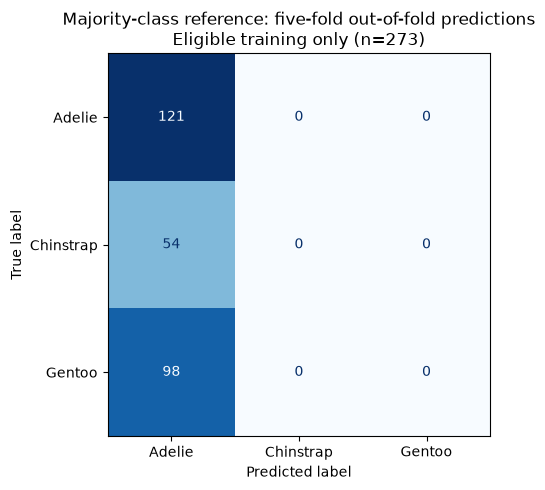

In [7]:
pooled_accuracy = accuracy_score(y_train, oof_predictions)
pooled_macro_f1 = f1_score(y_train, oof_predictions, labels=CLASS_ORDER, average='macro', zero_division=0)
pooled_results = pd.DataFrame({'accuracy': [pooled_accuracy], 'macro_F1': [pooled_macro_f1]},
                              index=['Pooled out-of-fold reference'])
precision, recall, per_class_f1, support = precision_recall_fscore_support(
    y_train, oof_predictions, labels=CLASS_ORDER, average=None, zero_division=0)
reference_species_scores = pd.DataFrame({
    'precision': precision, 'recall': recall, 'F1': per_class_f1, 'support': support,
}, index=CLASS_ORDER)
print('Read one species at a time: ordinary precision, recall and F1')
display(reference_species_scores.round(4))
print('Macro-F1 = mean of these three F1 scores:', per_class_f1.mean().round(4))
assert np.isclose(per_class_f1.mean(), pooled_macro_f1)

print('Summary; macro_F1 means the equal-weight mean of the three species F1 scores')
display(pooled_results.round(4))
display(fold_results[['accuracy', 'macro_F1']].agg(['mean', 'std']).rename(index={'std': 'sample_std_across_folds'}).round(4))

matrix = confusion_matrix(y_train, oof_predictions, labels=CLASS_ORDER)
assert int(matrix.sum()) == len(y_train)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matrix, display_labels=CLASS_ORDER).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Majority-class reference: five-fold out-of-fold predictions\nEligible training only (n=273)')
fig.tight_layout()
plt.show()

## 9. Interpret the reference results

All five fit groups have Adelie as their majority species. Predicting only Adelie gives 121/273 correct (**44.32% accuracy**), but misses every Chinstrap and Gentoo. The ordinary F1 scores are **0.6142, 0 and 0**. Their mean, **0.2047**, is the macro-F1 summary.

This is a comparison point, not useful recognition from measurements. A later model must improve held-out predictions on the same rows and folds, rather than merely obtain a high score on the rows used to fit it. The next sections perform that comparison. These results are conditional on complete inputs and this sample; they are not final-test performance.

## 10. Logistic regression: coefficients, probabilities and species

**First understand the binary idea.** Imagine a qualitative response with two possible labels, coded 0 and 1. A logistic model converts a linear score into the probability of class 1:

$$a(x)=\beta_0+\beta_1x_1+\cdots+\beta_px_p,\qquad p(x)=\frac{1}{1+\exp[-a(x)]}.$$

The S-shaped function is the **sigmoid**. Here $p$ in the sum is the number of predictors, whereas $p(x)$ denotes a probability. The intercept $\beta_0$ shifts the score; $\beta_j$ describes the contribution of predictor $j$ while the others are held fixed. These coefficients are learned from labelled fit observations. They are not causal effects.

The associated **log-odds**, or logit, is linear:

$$\log\frac{p(x)}{1-p(x)}=\beta_0+\sum_{j=1}^{p}\beta_jx_j.$$

For a binary decision one could compare $p(x)$ with a threshold. This is an explanation of the binary model, **not a change to our target or a new binary experiment**.

**Our actual task has three species.** The multinomial model extends this idea to a score for each species. Because we standardise our four measurements, write the fitted input as $z$:

$$a_k(z)=\beta_{0k}+\sum_{j=1}^{4}\beta_{jk}z_j,\qquad p_k(z)=\frac{\exp[a_k(z)]}{\sum_{r=1}^{3}\exp[a_r(z)]}.$$

This normalisation is **softmax**. The probabilities sum to one, and prediction chooses the most probable species: $\widehat y=\operatorname*{arg\,max}_k p_k(z)$. Illustrative probabilities $(0.10,0.75,0.15)$ predict Chinstrap; we do not apply separate 0.5 thresholds to three species.

The implementation stores three rows of four coefficients in `coef_` and three intercepts in `intercept_`. Earlier notation $w_{kj}$ and $b_k$ means the same coefficient and intercept roles. There are other multinomial parameterisations, so raw coefficients from differently parameterised models should not be compared directly. Logistic regression is a classification model here, not a neural network.

### 10.1 Learning coefficients: likelihood, loss and optimisation

**Maximum likelihood** chooses coefficients that make the observed fit labels probable. In the binary explanation, the likelihood is

$$\mathcal L(\beta)=\prod_{i=1}^{m}p_i^{y_i}(1-p_i)^{1-y_i},\qquad p_i=p(x_i).$$

Here $m$ is the number of fit observations and $y_i$ is 0 or 1 in this binary illustration. Taking a logarithm preserves the maximiser. Changing its sign turns maximisation into minimisation of **negative log-likelihood**, also called binary cross-entropy:

$$L(\beta)=-\sum_{i=1}^{m}[y_i\log p_i+(1-y_i)\log(1-p_i)].$$

For the actual three-species model, each observation contributes the negative log probability assigned to its true species. With our existing L2 regularisation the summed objective is

$$J(\beta)=-\sum_{i=1}^{m}\log p_{i,y_i}+\frac{1}{2C}\sum_{k=1}^{3}\sum_{j=1}^{4}\beta_{jk}^{2}.$$

The first term penalises wrong probabilities. Assigning the true class probability 0.9 gives log-loss about 0.105; assigning 0.1 gives about 2.303. The second term discourages large coefficients; the intercepts are not penalised by our solver. Lower loss is better, but numerical convergence does not guarantee good validation performance.

**Basic optimisation idea: gradient descent.** For a differentiable loss $L$, a parameter update is

$$\beta^{(t+1)}=\beta^{(t)}-\eta\,\nabla L(\beta^{(t)}).$$

The gradient contains the loss derivatives; subtracting a small multiple moves in a locally decreasing direction. $\eta$ is the learning rate, not a learned coefficient. A step that is too large can fail to reduce loss.

**Tiny conceptual example, not another fit of Penguins:** keep the intercept fixed at 0, take one binary observation $x=1,y=1$, set its coefficient to 0 and use $\eta=0.1$. Then $p=0.5$, the unregularised loss derivative is $(p-y)x=-0.5$, and one gradient step gives $\beta_{\mathrm{new}}=0-0.1(-0.5)=0.05$. This shows how a coefficient can change during training.

**What our code actually runs:** `model.fit(X_fit, y_fit)` first learns fit-only scaling and then minimises the regularised multinomial objective using the library's **L-BFGS solver**. It uses derivatives and an approximation to curvature; it is not the simple fixed-learning-rate update above. We have not changed the solver, added SGD or chosen a learning rate for the existing experiment. `max_iter=1000` is a stopping ceiling, not 1000 mandatory epochs. The coefficients displayed later are the learned values from round 1.

The saved execution was verified locally on the author's computer. Running the notebook in Colab trains it in Colab's runtime; opening saved outputs alone trains nothing.

### 10.2 Parameters, hyperparameters and what we may change

| Item | Current choice | Meaning |
|---|---|---|
| Learned parameters | `coef_`, `intercept_` | Numerical values learned by each `fit`; we do not type them manually. |
| `C` | `1.0` | Inverse regularisation strength. Smaller: stronger penalty. Larger: weaker penalty. |
| `solver` | `'lbfgs'` | Chooses the numerical optimiser; supports our three species together. |
| `max_iter` | `1000` | Maximum solver iterations; not a model depth or epoch requirement. |
| `tol` | `1e-4` | Numerical stopping tolerance, not a required prediction error. |
| Regularisation | Default L2 | Discourages large coefficients; no automatic feature deletion. |
| Class weighting | None | No additional class weighting or artificial balancing. |
| Validation design | Five stratified folds, seed 42 | Controls assessment and reproducibility, not the learned coefficients. |

**Parameter optimisation is not hyperparameter tuning.** The optimiser learns coefficients inside every `fit` with fixed settings. The nested extension in section 32 compares `C` values 0.1, 1 and 10 using inner training-validation folds, then selects a setting within each outer fitting group. A grid search automates those repeated fits; it does not replace the optimiser inside each fit. This section first presents the fixed C=1 comparison; its scores remain separate from that later tuned procedure.

Do not change settings repeatedly until the displayed score looks good. The nested search records its candidates and selection rule, fits preprocessing inside every inner fold, and keeps the final test out of selection. Scores used to select a setting remain development scores. The original model settings stay fixed; a separately labelled tree-depth search appears below.

**Regularisation notation:** a general objective is loss plus a penalty weighted by $\lambda$. Larger $\lambda$ means stronger shrinkage. Our library exposes `C`, for which smaller values mean stronger regularisation. They play inverse-strength roles, but an exact numerical relationship depends on how loss and penalty are normalised; do not identify `C` with $\lambda$. Standardisation matters because a coefficient penalty depends on the units of the inputs.

## 11. The actual training code: scale, fit, predict

Body mass is in grams, while bill dimensions are in millimetres. For each input $j$, StandardScaler learns the fit set's mean and population standard deviation:

$$\mu_j=\frac{1}{m}\sum_{i=1}^{m}x_{ij},\qquad \sigma_j=\sqrt{\frac{1}{m}\sum_{i=1}^{m}(x_{ij}-\mu_j)^2},\qquad z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.$$

A constant input is handled with scale 1 by the library. Scaling makes the coefficient penalty comparable across measurement units and helps numerical optimisation. It does not make a variable Gaussian or remove outliers.

**Read the loop in this order:**
1. `Pipeline(...)`: create a **fresh, unfitted** scaler and classifier.
2. Select this round's fit rows and validation rows from the fixed folds.
3. `model.fit(X_fit, y_fit)`: learn fit-only scaling, then optimise logistic coefficients and intercepts. **This is where training happens.**
4. `model.predict(X_validation)`: reuse those fitted quantities and produce held-out labels. **No learning happens here.**
5. `model.predict_proba(X_validation)`: return the held-out class probabilities, again without fitting.
6. Compare predictions with the validation labels and save one prediction per row. Repeat for the five rounds.

Do not scale all 273 rows before splitting the folds: validation values would then influence learned preprocessing. The code checks the scaler's statistics against each fit subset and stops on a convergence warning.

The output first compares fit and validation scores. It then shows scaling statistics and learned coefficients **from round 1 only**. These are real fitted values, not a final all-training model. Each of the other four rounds learns its own quantities. Increasing an input changes relative class scores through its coefficients; coefficient size is not automatically causal or universal feature importance.

In [8]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_oof = pd.Series(index=y_train.index, dtype='object', name='logistic_prediction')
logistic_probabilities = pd.DataFrame(np.nan, index=y_train.index, columns=CLASS_ORDER)
logistic_coverage = np.zeros(len(X_train), dtype=int)
logistic_rows = []

for fold_number, (fit_positions, validation_positions) in enumerate(folds, start=1):
    model = Pipeline([
        ('scale', StandardScaler()),
        ('classifier', LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, tol=1e-4)),
    ])
    X_fit, y_fit = X_train.iloc[fit_positions], y_train.iloc[fit_positions]
    X_validation, y_validation = X_train.iloc[validation_positions], y_train.iloc[validation_positions]
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        # TRAIN HERE: fit-only scaling, then optimise classifier coefficients/intercepts.
        model.fit(X_fit, y_fit)
    # EVALUATE HERE: reuse learned quantities; validation never refits the model.
    predictions = model.predict(X_validation)
    probabilities = pd.DataFrame(model.predict_proba(X_validation),
                                 index=X_validation.index, columns=model.classes_)
    logistic_oof.iloc[validation_positions] = predictions
    logistic_probabilities.loc[X_validation.index, CLASS_ORDER] = probabilities[CLASS_ORDER]
    logistic_coverage[validation_positions] += 1
    fit_predictions = model.predict(X_fit)
    logistic_rows.append({
        'fold': fold_number,
        'fit_accuracy': accuracy_score(y_fit, fit_predictions),
        'validation_accuracy': accuracy_score(y_validation, predictions),
        'fit_macro_F1': f1_score(y_fit, fit_predictions, labels=CLASS_ORDER, average='macro', zero_division=0),
        'validation_macro_F1': f1_score(y_validation, predictions, labels=CLASS_ORDER, average='macro', zero_division=0),
        'solver_iterations': int(model.named_steps['classifier'].n_iter_.max()),
    })
    # A direct check: scaler statistics equal this fold's fit inputs, not all training rows.
    np.testing.assert_allclose(model.named_steps['scale'].mean_, X_fit.mean().to_numpy())
    np.testing.assert_allclose(model.named_steps['scale'].var_, X_fit.var(ddof=0).to_numpy())
    assert int(model.named_steps['scale'].n_samples_seen_) == len(X_fit)
    if fold_number == 1:
        classifier = model.named_steps['classifier']
        first_fold_coefficients = pd.DataFrame(classifier.coef_, index=classifier.classes_, columns=FEATURES)
        first_fold_intercepts = pd.Series(classifier.intercept_, index=classifier.classes_, name='intercept')
        first_fold_scaling = pd.DataFrame({'fit_mean': model.named_steps['scale'].mean_,
                                          'fit_std': model.named_steps['scale'].scale_}, index=FEATURES)

assert (logistic_coverage == 1).all() and logistic_oof.notna().all()
assert logistic_probabilities.notna().all().all()
assert ((logistic_probabilities >= 0) & (logistic_probabilities <= 1)).all().all()
np.testing.assert_allclose(logistic_probabilities.sum(axis=1), 1.0)
assert (logistic_probabilities.idxmax(axis=1) == logistic_oof).all()
logistic_fold_results = pd.DataFrame(logistic_rows).set_index('fold')
display(logistic_fold_results.round(4))
print('Scaling example: statistics learned from the first fit fold only')
display(first_fold_scaling.round(4))
print('Learned coefficients from round 1: rows = species, columns = standardised inputs')
display(first_fold_coefficients.round(4))
print('Learned intercepts from round 1')
display(first_fold_intercepts.round(4).to_frame())

,fit_accuracy,validation_accuracy,fit_macro_F1,validation_macro_F1,solver_iterations
fold,,,,,
1,0.9862,1.0000,0.9831,1.0000,11
2,0.9862,1.0000,0.9831,1.0000,11
3,0.9862,0.9636,0.9831,0.9533,11
4,0.9909,0.9630,0.9888,0.9528,11
5,0.9817,1.0000,0.9773,1.0000,11


Scaling example: statistics learned from the first fit fold only


,fit_mean,fit_std
bill_length_mm,44.0450,5.4062
bill_depth_mm,17.1358,2.0635
flipper_length_mm,200.8211,13.6832
body_mass_g,4219.2661,787.6675


Learned coefficients from round 1: rows = species, columns = standardised inputs


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
Adelie,-2.3498,1.4109,-0.4993,0.4019
Chinstrap,2.0462,0.2474,-0.6114,-1.3537
Gentoo,0.3036,-1.6583,1.1107,0.9518


Learned intercepts from round 1


,intercept
Adelie,0.4249
Chinstrap,-0.1561
Gentoo,-0.2688


## 12. Evaluate without fitting again

We now have one held-out prediction from each method for every eligible training observation. We first show **precision, recall and F1 for each species**, then an overall accuracy and the explicitly labelled mean F1 (macro-F1). The same rows and folds make the comparison fair.

**Worked logistic example: Chinstrap versus the other species.** The confusion matrix gives $TP=51$, $FP=1$ (one Adelie called Chinstrap), and $FN=3$ (three Chinstrap called Adelie):

$$P=\frac{51}{52}=0.9808,\qquad R=\frac{51}{54}=0.9444,\qquad F1=\frac{102}{102+1+3}=0.9623.$$

The other F1 scores are 0.9836 for Adelie and 1.0000 for Gentoo. Their equal-weight mean is 0.9820. This explains the summary using the ordinary per-species F1 values.

The matrix contains counts with true species on rows and predicted species on columns. Fold means and sample standard deviations are secondary descriptive summaries, not confidence intervals. Fit scores can help discuss overfitting, but only held-out scores assess these development predictions. No final-test result appears here.

,precision,recall,F1,support
Adelie,0.9756,0.9917,0.9836,121
Chinstrap,0.9808,0.9444,0.9623,54
Gentoo,1.0000,1.0000,1.0000,98


F1 comparison by species; no averaging in these three rows


,reference_F1,logistic_F1
Adelie,0.614213,0.983607
Chinstrap,0.000000,0.962264
Gentoo,0.000000,1.000000


Mean of the three logistic F1 scores (macro-F1): 0.982


,accuracy,macro_F1
Majority reference,0.4432,0.2047
Logistic regression,0.9853,0.9820


,validation_accuracy,validation_macro_F1
mean,0.9853,0.9812
std,0.0201,0.0257


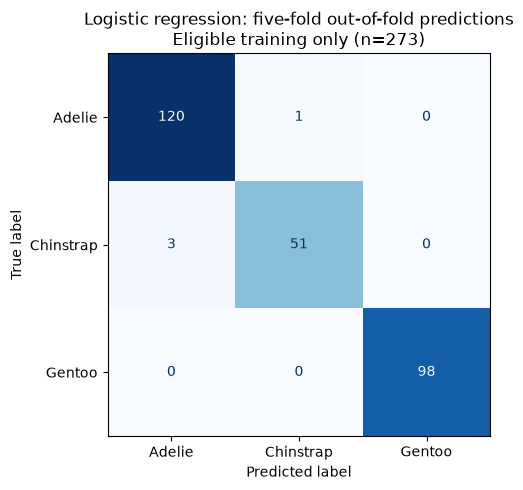

Correct / incorrect: 269 4


In [9]:
# Ordinary metrics for each species, before any averaging.
log_precision, log_recall, log_f1, log_support = precision_recall_fscore_support(
    y_train, logistic_oof, labels=CLASS_ORDER, average=None, zero_division=0)
logistic_species_scores = pd.DataFrame({
    'precision': log_precision, 'recall': log_recall, 'F1': log_f1, 'support': log_support,
}, index=CLASS_ORDER)
display(logistic_species_scores.round(4))
print('F1 comparison by species; no averaging in these three rows')
display(pd.DataFrame({'reference_F1': reference_species_scores['F1'],
                      'logistic_F1': logistic_species_scores['F1']}))
print('Mean of the three logistic F1 scores (macro-F1):', log_f1.mean().round(4))

comparison = pd.DataFrame({
    'Majority reference': {'accuracy': accuracy_score(y_train, oof_predictions),
                           'macro_F1': f1_score(y_train, oof_predictions, labels=CLASS_ORDER, average='macro', zero_division=0)},
    'Logistic regression': {'accuracy': accuracy_score(y_train, logistic_oof),
                            'macro_F1': f1_score(y_train, logistic_oof, labels=CLASS_ORDER, average='macro', zero_division=0)},
}).T
display(comparison.round(4))
display(logistic_fold_results[['validation_accuracy', 'validation_macro_F1']].agg(['mean', 'std']).round(4))
logistic_matrix = confusion_matrix(y_train, logistic_oof, labels=CLASS_ORDER)
assert int(logistic_matrix.sum()) == len(y_train)
# Recalculate per-species F1 directly from the confusion counts.
true_positives = np.diag(logistic_matrix)
false_positives = logistic_matrix.sum(axis=0) - true_positives
false_negatives = logistic_matrix.sum(axis=1) - true_positives
manual_f1 = 2 * true_positives / (2 * true_positives + false_positives + false_negatives)
np.testing.assert_allclose(manual_f1, log_f1)
assert np.isclose(manual_f1.mean(), comparison.loc['Logistic regression', 'macro_F1'])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(logistic_matrix, display_labels=CLASS_ORDER).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Logistic regression: five-fold out-of-fold predictions\nEligible training only (n=273)')
fig.tight_layout()
plt.show()
print('Correct / incorrect:', int((logistic_oof == y_train).sum()), int((logistic_oof != y_train).sum()))

## 13. Read probabilities and individual errors

The first five source IDs below are chosen by source order, not confidence or correctness. Each row's probabilities come from its held-out fold. We also list **all** misclassified training observations, with their original physical measurements. These are development errors, not test examples. They may suggest overlap or model limitations, but do not justify silently deleting rows or retuning this comparison.

A high model probability is not proof of certainty or calibration. `predict_proba` normalises class scores; it does not guarantee that 90% predictions are correct 90% of the time. We have not tested calibration.

In [10]:
prediction_examples = logistic_probabilities.copy()
prediction_examples.columns = ['P(' + label + ')' for label in CLASS_ORDER]
prediction_examples.insert(0, 'true_species', y_train)
prediction_examples.insert(1, 'predicted_species', logistic_oof)
print('First five held-out examples in source-row order')
display(prediction_examples.head(5).round(4))
errors = X_train.loc[logistic_oof != y_train].copy()
errors['true_species'] = y_train.loc[errors.index]
errors['predicted_species'] = logistic_oof.loc[errors.index]
print('All held-out classification errors:', len(errors))
display(errors)

First five held-out examples in source-row order


,true_species,predicted_species,P(Adelie),P(Chinstrap),P(Gentoo)
0,Adelie,Adelie,0.9867,0.0131,0.0002
2,Adelie,Adelie,0.8631,0.1331,0.0038
4,Adelie,Adelie,0.9974,0.0025,0.0001
5,Adelie,Adelie,0.9944,0.0056,0.0000
6,Adelie,Adelie,0.9755,0.0238,0.0007


All held-out classification errors: 4


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,true_species,predicted_species
73,45.8,18.9,197.0,4150.0,Adelie,Chinstrap
296,42.4,17.3,181.0,3600.0,Chinstrap,Adelie
306,40.9,16.6,187.0,3200.0,Chinstrap,Adelie
340,43.5,18.1,202.0,3400.0,Chinstrap,Adelie


## 14. What we have learned, and what we have not

**Result:** logistic regression gets 269/273 held-out observations correct (**98.53% accuracy**), versus 121/273 (**44.32%**) for the majority reference. The F1 scores for Adelie, Chinstrap and Gentoo are **0.9836, 0.9623 and 1.0000**; their equal-weight mean is **0.9820**. The reference's F1 scores are **0.6142, 0 and 0**, with mean **0.2047**.

**Errors:** one Adelie is called Chinstrap and three Chinstrap are called Adelie. All 98 Gentoo are correctly classified in these folds; that does not prove perfect Gentoo classification in new data. The remaining confusion is compatible with the EDA's overlap between groups, but that is not a demonstrated cause for each error. We do not delete those observations or tune settings in response.

**Training versus validation:** we fitted five versions per method on overlapping fit subsets. Logistic fit accuracy ranges from 98.17% to 99.09%; validation is 100% in three rounds and about 96.3% in two. Validation can exceed fit accuracy because the subsets differ. A small gap does not prove absence of overfitting. The saved execution reports 11 solver iterations per round and no convergence warning.

**Scope:** parameters were optimised inside each fit with fixed hyperparameters. No broad hyperparameter search has run. These are development scores after training EDA, conditional on complete measurements and a small within-sample random split. No final-test result, calibrated-probability claim or transfer to new islands/years is established. This fixed-model block does not fit a final all-development model; the later final-fit block does. The following block adds a shallow tree as a learning comparison, not a large search.

## 15. A decision tree learns questions instead of coefficients

A classification tree predicts species using a sequence of **if/else rules**. At an internal node it asks whether one measurement is below a learned threshold. A terminal node, also called a **terminal region** or **leaf**, predicts the most frequent species among the fit observations reaching it. Start at the root and follow one branch at a time.

**What is learned?** The chosen input at each split, its threshold, the branching structure and the leaf class counts. We provide limits such as maximum depth; we do not manually provide its thresholds. Training happens at `tree.fit(X_fit, y_fit)`. Prediction follows the already learned rules and does not modify them.

Unlike logistic regression, this tree does **not** use L-BFGS, gradients or training epochs. Its CART procedure uses **top-down recursive binary splitting**: it greedily chooses the best permitted split at each node, then repeats within child nodes. A locally best split is not a guarantee of the globally best possible tree.

The tree uses the same four physical inputs, in their original units. It does not need standardisation: its splits depend on ordered values rather than distances or a penalty on input coefficients. Keeping original units makes the rules easier to read. This does not mean trees are immune to overfitting or data-quality problems.

### 15.1 Gini impurity: how mixed is a node?

Let $p_k$ be the fraction of fit observations in a node belonging to species $k$. For three species:

$$G=\sum_{k=1}^{3}p_k(1-p_k)=1-\sum_{k=1}^{3}p_k^2.$$

The two expressions are equal because the class proportions sum to one. This connects the **Gini index** to node purity. A pure node, containing only one species, has $G=0$. Equal proportions give $G=2/3$, the maximum for three classes. **Impurity is not the classification error or a validation metric.**

For a proposed split into left and right children:

$$G_{\mathrm{children}}=\frac{n_L}{n}G_L+\frac{n_R}{n}G_R,\qquad \Delta G=G_{\mathrm{parent}}-G_{\mathrm{children}}.$$

Here $n=n_L+n_R$. The algorithm prefers the largest impurity reduction among the permitted input/threshold choices at that node, using **fit labels only**, not validation labels.

**Small numerical example, not a result from Penguins:** a node has species counts $(4,3,3)$, hence $G=1-(0.4^2+0.3^2+0.3^2)=0.66$. A candidate split gives left counts $(4,1,0)$ and right counts $(0,2,3)$. Their impurities are 0.32 and 0.48. Both children have five observations, so weighted impurity is $0.5(0.32)+0.5(0.48)=0.40$ and gain is $0.66-0.40=0.26$.

After fitting, we also calculate this reduction at the **actual first-fold root**. That checks how the formula connects to the fitted tree, not whether this is the best model.

### 15.2 Fixed settings before running the comparison

| Hyperparameter | Value | Meaning |
|---|---|---|
| `criterion` | `'gini'` | Use Gini impurity to compare splits. |
| `splitter` | `'best'` | Find the best permitted split at each node, greedily. |
| `max_depth` | `3` | At most three successive splits along a root-to-leaf path; root depth is zero. |
| `min_samples_leaf` | `5` | A split must leave at least five fit observations in each child. |
| `random_state` | `42` | Reproducible handling of feature order/ties. |

Other settings retain library defaults, including all four candidate inputs at each split, no class weighting and no additional cost-complexity pruning. Depth 3 and five observations per leaf are **simple teaching choices**, not tuned optima. A depth limit of three permits at most eight leaves; it does not force that many.

A deeper tree or smaller minimum leaf size permits more detailed rules and can increase overfitting; tighter limits can underfit. This initial comparison fixes depth 3. The separate four-depth search below evaluates this setting against alternatives within development, without opening the final test.

Depth and leaf limits stop growth early. They differ from growing a larger tree and applying cost-complexity pruning afterwards; no pruning-path search is performed.

## 16. Train five fresh trees on the original folds

We reuse `folds` from section 6 and the same 273 complete-measurement observations. Every round creates a fresh tree, fits it on 218 or 219 rows and validates on the other 54 or 55. No scaler or additional data preparation is fitted here.

Read the two important lines: `tree.fit(...)` **learns the rules**; `tree.predict(...)` **uses those rules without learning**. We save one held-out prediction per row. Fit scores and validation scores are shown separately, followed by each tree's actual depth and leaf count.

We retain the first fitted tree for illustration, chosen by **fold number**, not by its score. It is not a final model fitted on all training rows.

In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

tree_oof = pd.Series(index=y_train.index, dtype='object', name='tree_prediction')
tree_coverage = np.zeros(len(X_train), dtype=int)
tree_rows = []

for fold_number, (fit_positions, validation_positions) in enumerate(folds, start=1):
    tree = DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=3,
                                  min_samples_leaf=5, random_state=SEED)
    X_fit, y_fit = X_train.iloc[fit_positions], y_train.iloc[fit_positions]
    X_validation, y_validation = X_train.iloc[validation_positions], y_train.iloc[validation_positions]
    # TRAIN HERE: choose inputs/thresholds and learn the leaves from this fit subset.
    tree.fit(X_fit, y_fit)
    # PREDICT HERE: follow fitted rules; no validation information is learned.
    held_out = tree.predict(X_validation)
    fit_predictions = tree.predict(X_fit)
    tree_oof.iloc[validation_positions] = held_out
    tree_coverage[validation_positions] += 1
    tree_rows.append({
        'fold': fold_number,
        'fit_accuracy': accuracy_score(y_fit, fit_predictions),
        'validation_accuracy': accuracy_score(y_validation, held_out),
        'fit_mean_F1': f1_score(y_fit, fit_predictions, labels=CLASS_ORDER, average='macro', zero_division=0),
        'validation_mean_F1': f1_score(y_validation, held_out, labels=CLASS_ORDER, average='macro', zero_division=0),
        'depth': tree.get_depth(), 'leaves': tree.get_n_leaves(),
    })
    assert tree.get_depth() <= 3
    leaf_mask = tree.tree_.children_left == -1
    assert (tree.tree_.n_node_samples[leaf_mask] >= 5).all()
    assert set(X_fit.index).isdisjoint(test_ids)
    assert set(X_validation.index).isdisjoint(test_ids)
    if fold_number == 1:
        first_tree = tree
        first_tree_fit_X = X_fit.copy()
        first_tree_fit_y = y_fit.copy()

assert (tree_coverage == 1).all() and tree_oof.notna().all()
tree_fold_results = pd.DataFrame(tree_rows).set_index('fold')
print('mean_F1 = equal-weight mean of the three species F1 scores (macro-F1)')
display(tree_fold_results.round(4))

mean_F1 = equal-weight mean of the three species F1 scores (macro-F1)


,fit_accuracy,validation_accuracy,fit_mean_F1,validation_mean_F1,depth,leaves
fold,,,,,,
1,0.9541,0.9818,0.9447,0.9776,3,6
2,0.9679,0.9273,0.9620,0.9184,3,5
3,0.9541,0.9091,0.9442,0.8654,3,6
4,0.9589,0.8889,0.9501,0.8691,3,6
5,0.9635,0.9074,0.9579,0.8987,3,6


## 17. Evaluate the tree and compare all three methods

First read ordinary precision, recall and F1 **for each species**. Then compare accuracy and the explicitly labelled mean of species F1 scores. We do not replace these with fit-set scores.

The confusion matrix has true species on rows and predictions on columns. Its counts sum to 273. The table below uses the same observations and folds for the majority reference, logistic regression and the tree. This is a limited development comparison, not a ranking of every possible version of these algorithms or a final-test result.

,precision,recall,F1,support
Adelie,0.9268,0.9421,0.9344,121
Chinstrap,0.8462,0.8148,0.8302,54
Gentoo,0.9592,0.9592,0.9592,98


Per-species F1: no averaging in these three rows


,reference_F1,logistic_F1,tree_F1
Adelie,0.6142,0.9836,0.9344
Chinstrap,0.0000,0.9623,0.8302
Gentoo,0.0000,1.0000,0.9592


Held-out development summary; mean_species_F1 is macro-F1


,accuracy,mean_species_F1
Majority reference,0.4432,0.2047
Logistic regression,0.9853,0.9820
Decision tree (depth <= 3),0.9231,0.9079


,validation_accuracy,validation_mean_F1
mean,0.9229,0.9058
std,0.0356,0.0457


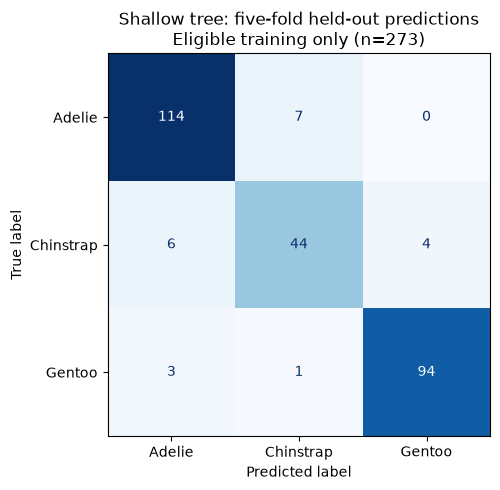

Correct / incorrect: 252 21


In [12]:
tree_precision, tree_recall, tree_f1, tree_support = precision_recall_fscore_support(
    y_train, tree_oof, labels=CLASS_ORDER, average=None, zero_division=0)
tree_species_scores = pd.DataFrame({'precision': tree_precision, 'recall': tree_recall,
                                   'F1': tree_f1, 'support': tree_support}, index=CLASS_ORDER)
display(tree_species_scores.round(4))
print('Per-species F1: no averaging in these three rows')
display(pd.DataFrame({'reference_F1': reference_species_scores['F1'],
                      'logistic_F1': logistic_species_scores['F1'],
                      'tree_F1': tree_species_scores['F1']}).round(4))
all_model_comparison = comparison.rename(columns={'macro_F1': 'mean_species_F1'}).copy()
all_model_comparison.loc['Decision tree (depth <= 3)'] = [
    accuracy_score(y_train, tree_oof), tree_f1.mean()]
print('Held-out development summary; mean_species_F1 is macro-F1')
display(all_model_comparison.round(4))
display(tree_fold_results[['validation_accuracy', 'validation_mean_F1']].agg(['mean', 'std']).round(4))
tree_matrix = confusion_matrix(y_train, tree_oof, labels=CLASS_ORDER)
assert tree_matrix.sum() == len(y_train)
tp = np.diag(tree_matrix)
manual_tree_f1 = 2 * tp / (tree_matrix.sum(axis=0) + tree_matrix.sum(axis=1))
np.testing.assert_allclose(manual_tree_f1, tree_f1)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(tree_matrix, display_labels=CLASS_ORDER).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Shallow tree: five-fold held-out predictions' + chr(10) + 'Eligible training only (n=273)')
fig.tight_layout()
plt.show()
print('Correct / incorrect:', int((tree_oof == y_train).sum()), int((tree_oof != y_train).sum()))

## 18. Read the first-fold tree, not a specially selected winner

The diagram and text rules below show **the tree fitted in round 1**, using that round's fit rows only. Other rounds may learn different rules.

- A decision box asks `measurement <= threshold`. **True goes left; false goes right.** Thresholds remain in millimetres or grams.
- `gini` is the mixture of fit classes at that node, not validation error.
- `samples` counts fit observations reaching the node, not the whole dataset.
- `value` lists fit class counts in the displayed class order; `class` is the majority prediction. A pure leaf need not predict new observations perfectly.

Follow one path from root to leaf, reading each condition in order. The code also walks the **first source-row observation in round 1's validation group**, selected before checking its correctness. It prints the actual tests and resulting prediction, without refitting. This illustrates one decision, not the explanation for every prediction.

Finally, the root table recalculates Gini directly from first-fold fit labels. Its weighted-child impurity and gain should match the fitted tree. A variable absent from this particular tree is not therefore proved irrelevant.

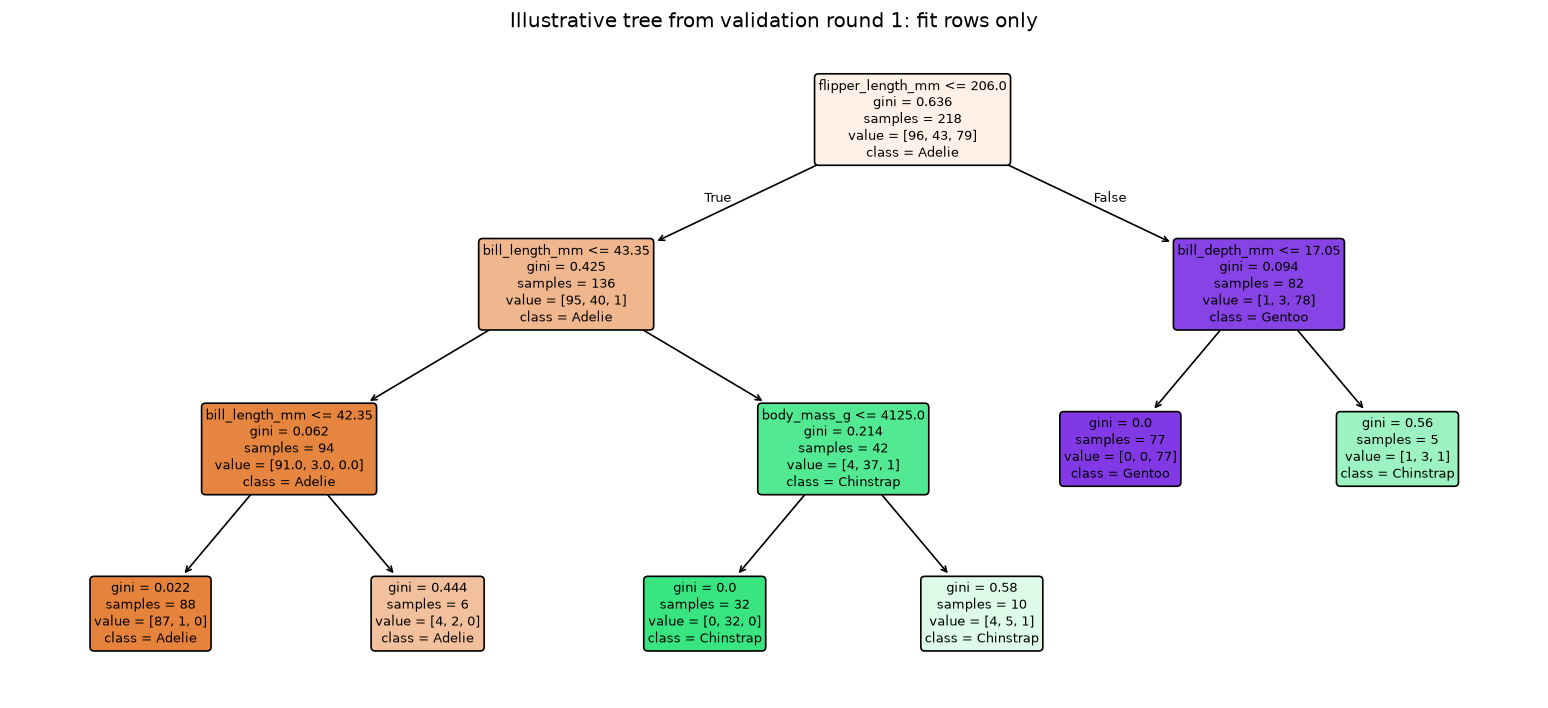

Class order: ['Adelie', 'Chinstrap', 'Gentoo']
|--- flipper_length_mm <= 206.00
|   |--- bill_length_mm <= 43.35
|   |   |--- bill_length_mm <= 42.35
|   |   |   |--- class: Adelie
|   |   |--- bill_length_mm >  42.35
|   |   |   |--- class: Adelie
|   |--- bill_length_mm >  43.35
|   |   |--- body_mass_g <= 4125.00
|   |   |   |--- class: Chinstrap
|   |   |--- body_mass_g >  4125.00
|   |   |   |--- class: Chinstrap
|--- flipper_length_mm >  206.00
|   |--- bill_depth_mm <= 17.05
|   |   |--- class: Gentoo
|   |--- bill_depth_mm >  17.05
|   |   |--- class: Chinstrap

Round-1 validation example, source ID: 4
flipper_length_mm = 193.0 <= 206.0 -> True
bill_length_mm = 36.7 <= 43.35 -> True
bill_length_mm = 36.7 <= 42.35 -> True
Prediction: Adelie | True species: Adelie


,n,Adelie,Chinstrap,Gentoo,gini
node,,,,,
parent,218,96,43,79,0.6358
left,136,95,40,1,0.4255
right,82,1,3,78,0.0937


Root weighted child Gini / gain: 0.3007 0.3352


In [13]:
fig, ax = plt.subplots(figsize=(13, 6), dpi=120)
plot_tree(first_tree, feature_names=FEATURES, class_names=first_tree.classes_.tolist(),
          filled=True, rounded=True, precision=3, fontsize=8, ax=ax)
ax.set_title('Illustrative tree from validation round 1: fit rows only')
fig.tight_layout()
plt.show()
print('Class order:', first_tree.classes_.tolist())
print(export_text(first_tree, feature_names=FEATURES, decimals=2))

# One real validation-row path through this already fitted tree.
example_position = folds[0][1][0]
example = X_train.iloc[[example_position]]
print('Round-1 validation example, source ID:', example.index[0])
node = 0
while first_tree.tree_.children_left[node] != -1:
    feature_index = first_tree.tree_.feature[node]
    threshold = first_tree.tree_.threshold[node]
    observed = float(example.iloc[0, feature_index])
    goes_left = observed <= threshold
    print(FEATURES[feature_index], '=', observed, '<=', round(threshold, 3), '->', goes_left)
    node = first_tree.tree_.children_left[node] if goes_left else first_tree.tree_.children_right[node]
print('Prediction:', first_tree.predict(example)[0], '| True species:', y_train.iloc[example_position])

# Check root impurity from the fit observations, independently of tree_.impurity.
feature_index = first_tree.tree_.feature[0]
root_threshold = first_tree.tree_.threshold[0]
left = first_tree_fit_X.iloc[:, feature_index] <= root_threshold
root_rows = []
for group, labels in [('parent', first_tree_fit_y),
                      ('left', first_tree_fit_y.loc[left]),
                      ('right', first_tree_fit_y.loc[~left])]:
    counts = labels.value_counts().reindex(CLASS_ORDER, fill_value=0)
    gini = 1 - ((counts / len(labels)) ** 2).sum()
    root_rows.append({'node': group, 'n': len(labels), **counts.to_dict(), 'gini': gini})
root_check = pd.DataFrame(root_rows).set_index('node')
display(root_check.round(4))
weighted_children = (root_check.loc[['left', 'right'], 'n'] *
                     root_check.loc[['left', 'right'], 'gini']).sum() / root_check.loc['parent', 'n']
root_gain = root_check.loc['parent', 'gini'] - weighted_children
np.testing.assert_allclose(root_check.loc['parent', 'gini'], first_tree.tree_.impurity[0])
child_nodes = [first_tree.tree_.children_left[0], first_tree.tree_.children_right[0]]
np.testing.assert_allclose(root_check.loc[['left', 'right'], 'gini'], first_tree.tree_.impurity[child_nodes])
print('Root weighted child Gini / gain:', round(weighted_children, 4), round(root_gain, 4))

## 19. Interpretation: a readable tree is not automatically the best predictor

**Held-out result:** the fixed shallow tree gets **252/273 correct (92.31%)**, with **21 errors**. Its ordinary F1 scores are **0.9344 for Adelie, 0.8302 for Chinstrap and 0.9592 for Gentoo**; their equal-weight mean is **0.9079**. Logistic regression scores 98.53% accuracy and mean species F1 0.9820 on the same observations and folds; the majority reference scores 44.32% and 0.2047. These numbers describe these fixed configurations in development, not universal algorithm superiority.

**Where does it struggle?** Recalls are 114/121 for Adelie (94.21%), 44/54 for Chinstrap (81.48%) and 94/98 for Gentoo (95.92%). Chinstrap is the weakest class in this comparison. That is why per-species scores accompany the overall accuracy. We do not change the settings to conceal that outcome.

**Fit versus validation:** fit accuracy ranges from 95.41% to 96.79%, while validation accuracy ranges from 88.89% to 98.18%. Validation is lower in four rounds, but higher in one because subsets differ. The mean validation accuracy is 0.9229 (sample SD 0.0356); mean fold F1 is 0.9058 (SD 0.0457). Pooled F1 0.9079 is a different summary. These gaps suggest a generalisation limitation, but do not by themselves separate sampling variation, overfitting and an overly restrictive tree. The original comparison fixes depth 3; the separate depth search follows below.

**Read the actual rule:** in round 1 the root asks whether flipper length is at most 206 mm. Its 218 fit observations split into 136 left and 82 right. Root Gini is approximately 0.6358; weighted child Gini is 0.3007, giving a reduction of 0.3352. The tree has depth 3 and six leaves; across rounds there are five or six leaves. Some extra splits retain the same predicted class in both children because they can still reduce impurity and change class proportions.

**What we learn:** the tree gives readable, original-unit rules, but its interpretability did not make it outperform logistic regression here. We keep both results honestly. Neither model is a neural network; logistic coefficients are learned by L-BFGS, whereas tree rules are learned by greedy splitting. All inputs, eligibility decisions and folds remain unchanged. No causal claim, calibrated probability guarantee, final all-training refit or final-test evaluation follows from this comparison.

### 19.1 A small hyperparameter search: tree depth only

We compare **max_depth = 2, 3, 4, 5**, keeping Gini, best splitting, minimum leaf size 5 and seed 42 fixed. The four candidates and selection metric are specified before this search is run, after the earlier development comparisons were examined. This is not a blind or independent new experiment.

`GridSearchCV` fits fresh trees on the **same saved five classification folds** and ranks depths by **mean validation macro-F1**, the equal-weight mean of the species F1 scores in each fold, averaged over five folds. Accuracy remains part of the original fixed-model comparison; no additional metric is searched. If mean scores tie exactly, the first candidate in the ascending list is selected, favouring the shallower depth. There is no repeated expansion of the grid after seeing results.

Each candidate tree fit learns splits; the parameter search compares depth settings. This initial search has one validation level. `refit=False` prevents an additional fit on all training rows. `n_jobs=1` runs the 20 fits sequentially, and `error_score='raise'` stops on a fit error. No scaler is needed for these trees.

**Important:** scikit-learn calls validation scores `test_score` in `cv_results_`. Here those are our development-fold validation scores, **not the 69-row reserved final test**. The selected mean is optimistically selected from the same folds; it is not an independent final performance estimate or proof of improvement over logistic regression. Fold SD here uses the search tool's population-SD convention, not a confidence interval.

,max_depth,mean_fit_F1,mean_validation_F1,validation_F1_SD
0,2,0.9439,0.9052,0.0404
1,3,0.9518,0.9058,0.0409
2,4,0.9594,0.9137,0.0460
3,5,0.9594,0.9137,0.0460


Depth selected by the initial search (not the final classifier): 4
Selected mean validation F1: 0.9137
This initial block: 20 development fits, no all-development refit and no final-test score.


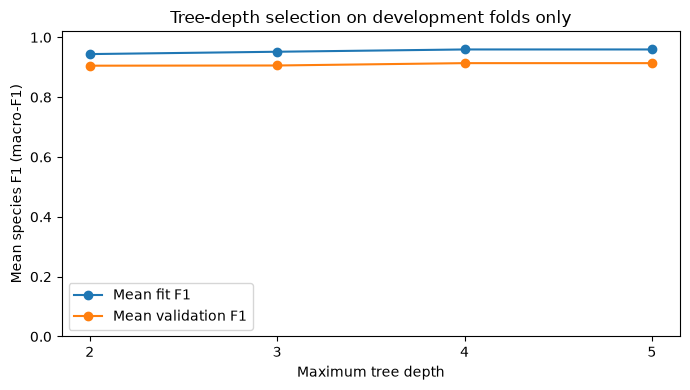

In [14]:
from sklearn.model_selection import GridSearchCV

depth_candidates = [2, 3, 4, 5]
depth_search = GridSearchCV(
    estimator=DecisionTreeClassifier(criterion='gini', splitter='best',
                                     min_samples_leaf=5, random_state=SEED),
    param_grid={'max_depth': depth_candidates},
    scoring='f1_macro', cv=folds, refit=False, n_jobs=1,
    return_train_score=True, error_score='raise',
)
# SEARCH HERE: each candidate depth triggers five independent tree fits.
depth_search.fit(X_train, y_train)
depth_cv = pd.DataFrame(depth_search.cv_results_)
depth_table = pd.DataFrame({
    'max_depth': depth_cv['param_max_depth'].astype(int),
    'mean_fit_F1': depth_cv['mean_train_score'],
    'mean_validation_F1': depth_cv['mean_test_score'],
    'validation_F1_SD': depth_cv['std_test_score'],
})
assert depth_table['max_depth'].tolist() == depth_candidates
assert depth_search.n_splits_ == 5 and len(depth_cv) == 4
assert not hasattr(depth_search, 'best_estimator_')  # No all-training refit.
assert set(X_train.index).isdisjoint(test_ids)
selected_depth = int(depth_search.best_params_['max_depth'])
selected_depth_score = float(depth_search.best_score_)
display(depth_table.round(4))
print('Depth selected by the initial search (not the final classifier):', selected_depth)
print('Selected mean validation F1:', round(selected_depth_score, 4))
print('This initial block: 20 development fits, no all-development refit and no final-test score.')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depth_table['max_depth'], depth_table['mean_fit_F1'], 'o-', label='Mean fit F1')
ax.plot(depth_table['max_depth'], depth_table['mean_validation_F1'], 'o-', label='Mean validation F1')
ax.set(xlabel='Maximum tree depth', ylabel='Mean species F1 (macro-F1)',
       title='Tree-depth selection on development folds only', xticks=depth_candidates,
       ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
plt.show()

### 19.2 Interpret the depth comparison

Mean validation F1 is **0.9052, 0.9058, 0.9137 and 0.9137** for depths 2, 3, 4 and 5. Depths **4 and 5 tie exactly**, so the ascending-candidate rule selects **4**. The gain over depth 3 is about **0.0079**, or 0.79 F1 percentage points, on these selection folds. This is a small development difference, not a confirmed improvement on independent data.

Mean fit F1 rises from 0.9439 at depth 2 to 0.9594 at depths 4/5. Training fit is better than validation on average; increasing permitted depth does not guarantee that validation will improve. Depths 4/5 yield the same fold scores here: a larger depth limit does not force the algorithm to grow an extra useful split under the other fixed restrictions. The reported SDs are descriptive, using GridSearchCV's population convention.

We retain the original fixed depth-3 comparison above as its own clearly labelled result. We do not replace it with the selected score or pretend that a depth-4 final model has been fitted: `refit=False` leaves no `best_estimator_`. Before final testing, any selected configuration must be frozen, fitted on eligible development data and evaluated once on the reserved observations. The later nested extension assesses a separate selection procedure and the selected classifier is then evaluated on the reserved test.

Tree fitting learns thresholds and leaves; the search compares fixed depth choices. Reserved-test rows stay outside both operations.

## 20. Linear SVM: separate classes with a margin

**Question:** can another classical classifier separate species using the same four measurements? We start with the **linear support vector classifier**, often called a linear SVM. A nonlinear kernel such as RBF is not used here.

First imagine just two classes, labelled $y_i\in\{-1,+1\}$ for the mathematics. In standardised coordinates $z$, a boundary is

$$f(z)=w^Tz+b=0.$$

In two dimensions this is a line; in four dimensions it is a hyperplane. The sign of the score chooses a side. Unlike logistic softmax output, this score is **not a probability**.

For perfectly separable binary data, the maximal-margin classifier chooses a separating boundary with the widest gap to the nearest observations. With the conventional boundaries $f(z)=+1$ and $f(z)=-1$, the **total margin width** is

$$\frac{2}{\lVert w\rVert}.$$

The sketch below uses hand-chosen two-dimensional points and $w=(1,0), b=0$: the boundary is $z_1=0$ and the margin width is 2. **It is a conceptual drawing, not Penguins data, not a trained model and not a projection of our four-dimensional fit.** Circled points illustrate support vectors on the margin. In the actual soft-margin model, support vectors may also lie inside the margin or on the wrong side; they are not simply all the errors.

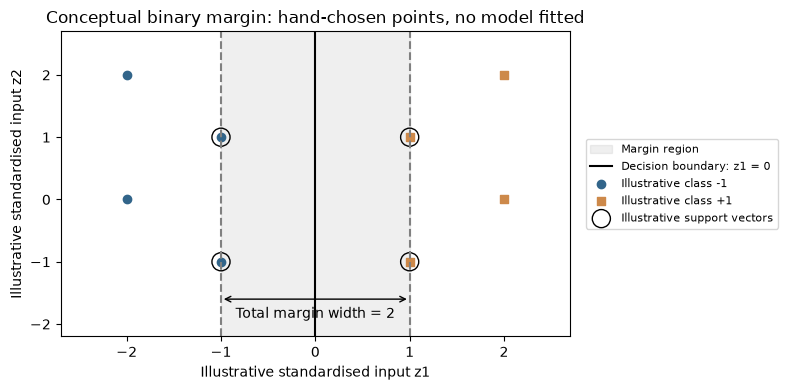

In [15]:
# A geometry illustration only: no estimator is fitted in this cell.
negative = np.array([[-1, -1], [-1, 1], [-2, 0], [-2, 2]])
positive = np.array([[1, -1], [1, 1], [2, 0], [2, 2]])
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(-1, 1, color='grey', alpha=0.12, label='Margin region')
ax.axvline(0, color='black', label='Decision boundary: z1 = 0')
for boundary in [-1, 1]:
    ax.axvline(boundary, color='grey', linestyle='--')
ax.scatter(negative[:, 0], negative[:, 1], label='Illustrative class -1', color='#32658a')
ax.scatter(positive[:, 0], positive[:, 1], label='Illustrative class +1', color='#cd894a', marker='s')
support_example = np.vstack([negative[:2], positive[:2]])
ax.scatter(support_example[:, 0], support_example[:, 1], s=170,
           facecolors='none', edgecolors='black', label='Illustrative support vectors')
ax.annotate('', xy=(1, -1.6), xytext=(-1, -1.6),
            arrowprops={'arrowstyle': '<->', 'color': 'black'})
ax.text(0, -1.9, 'Total margin width = 2', ha='center')
ax.set(xlabel='Illustrative standardised input z1', ylabel='Illustrative standardised input z2',
       title='Conceptual binary margin: hand-chosen points, no model fitted',
       xlim=(-2.7, 2.7), ylim=(-2.2, 2.7))
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.tight_layout()
plt.show()

### 20.1 Soft margins, learned parameters and fixed settings

Real classes can overlap. Instead of requiring perfect separation, a **soft margin** permits violations and penalises them. For one binary comparison, the objective is

$$\min_{w,b}\;\frac{1}{2}\lVert w\rVert^2+C\sum_i\max\bigl(0,1-y_i(w^Tz_i+b)\bigr).$$

The second term is **hinge loss**: it is zero when $y_if(z_i)\geq1$. A correctly classified point can still incur loss if it is inside the margin. For example, $y_i=+1$ and $f(z_i)=0.4$ gives loss $0.6$; $f(z_i)=1.4$ gives loss 0.

- **Learned during `fit`:** the boundary coefficients and intercept for each binary problem, represented through selected support vectors and learned weights. Support vectors are fit observations, not a special set taken from validation.
- **`C=1.0`:** fixed penalty multiplier in the objective above. Smaller `C` puts relatively more emphasis on a wide margin; larger `C` penalises violations more. Neither is automatically better on unseen data. C is fixed in this initial comparison; the nested extension later selects C from a small grid.
- **`kernel='linear'`:** uses $K(z_i,z_j)=z_i^Tz_j$, the dot product. It is not Pearson correlation. `gamma`, `degree` and `coef0` do not affect this linear kernel. We do not add an RBF experiment.
- **`tol=1e-3` and `max_iter=10000`:** solver stopping tolerance and iteration ceiling, not a number of epochs. Reaching the ceiling without convergence stops this notebook with an identifiable error.
- **`decision_function_shape='ovo'`:** makes score layout explicit. `SVC` fits one-versus-one internally: Adelie versus Chinstrap, Adelie versus Gentoo and Chinstrap versus Gentoo. Three pairwise classifiers vote for a species. This setting does not turn training into one-versus-rest. No probability calibration is enabled.

**How is it trained?** `SVC` uses LIBSVM's decomposition/SMO-type optimisation of the constrained problem. You do not need its derivation to follow this experiment: `fit` solves for the boundary after scaling. It is neither the logistic L-BFGS procedure nor tree splitting, and we do not supply a gradient-descent learning rate. `StandardScaler` matters because the margin depends on the units of the measurements. It must be fitted inside each fold.

These settings are fixed before the first SVM evaluation. This is a small teaching comparison, not tuning or a new independent evaluation: we have already examined the same development folds with other models.

## 21. Train five fresh linear SVM pipelines

The loop below reuses **exactly the same saved five folds**, four inputs and 273 eligible observations. Each round constructs a fresh scaler and classifier; its `model.fit(X_fit, y_fit)` line is where training happens. We fit only on that round's 218 or 219 observations, then predict its 54 or 55 held-out observations.

The scaler checks follow the logistic pipeline. We also check that every reported support vector belongs to that round's fit subset and that no fit or validation ID is a reserved test ID. Five validation rounds therefore fit fifteen binary boundaries in total, three per round. The diagram above fitted none.

The output separates fit accuracy from validation accuracy and records how many **distinct fit observations** are support vectors across the pairwise problems. The count is not a performance score and does not count validation observations. It may change between folds.

In [16]:
from sklearn.svm import SVC

svm_oof = pd.Series(index=y_train.index, dtype='object', name='linear_svm_prediction')
svm_coverage = np.zeros(len(X_train), dtype=int)
svm_rows = []

for fold_number, (fit_positions, validation_positions) in enumerate(folds, start=1):
    model = Pipeline([
        ('scale', StandardScaler()),
        ('classifier', SVC(C=1.0, kernel='linear', tol=1e-3,
                           max_iter=10000, decision_function_shape='ovo')),
    ])
    X_fit, y_fit = X_train.iloc[fit_positions], y_train.iloc[fit_positions]
    X_validation, y_validation = X_train.iloc[validation_positions], y_train.iloc[validation_positions]
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        # TRAIN HERE: learn fit-only scaling, then the pairwise SVM boundaries.
        model.fit(X_fit, y_fit)
    # PREDICT HERE: apply the fixed scaler and boundaries to held-out inputs.
    predictions = model.predict(X_validation)
    fit_predictions = model.predict(X_fit)
    svm_oof.iloc[validation_positions] = predictions
    svm_coverage[validation_positions] += 1
    scaler = model.named_steps['scale']
    classifier = model.named_steps['classifier']
    np.testing.assert_allclose(scaler.mean_, X_fit.mean().to_numpy())
    np.testing.assert_allclose(scaler.var_, X_fit.var(ddof=0).to_numpy())
    assert int(scaler.n_samples_seen_) == len(X_fit)
    assert classifier.fit_status_ == 0
    support_ids = X_fit.index[classifier.support_]
    assert set(support_ids).issubset(set(X_fit.index))
    assert set(support_ids).isdisjoint(X_validation.index)
    assert set(X_fit.index).isdisjoint(test_ids)
    assert set(X_validation.index).isdisjoint(test_ids)
    assert len(support_ids) == int(classifier.n_support_.sum())
    svm_rows.append({
        'fold': fold_number,
        'fit_accuracy': accuracy_score(y_fit, fit_predictions),
        'validation_accuracy': accuracy_score(y_validation, predictions),
        'validation_mean_F1': f1_score(y_validation, predictions, labels=CLASS_ORDER,
                                       average='macro', zero_division=0),
        'support_vectors': len(support_ids),
        'max_pairwise_iterations': int(classifier.n_iter_.max()),
    })
    if fold_number == 1:
        first_svm_support_counts = pd.Series(classifier.n_support_,
                                             index=classifier.classes_, name='fit_support_vectors')

assert (svm_coverage == 1).all() and svm_oof.notna().all()
svm_fold_results = pd.DataFrame(svm_rows).set_index('fold')
display(svm_fold_results.round(4))
print('Round 1: distinct support observations by species, from fit rows only')
display(first_svm_support_counts.to_frame())

,fit_accuracy,validation_accuracy,validation_mean_F1,support_vectors,max_pairwise_iterations
fold,,,,,
1,0.9908,1.0000,1.0000,22,108
2,0.9862,1.0000,1.0000,25,61
3,0.9862,0.9636,0.9533,24,137
4,0.9954,0.9630,0.9528,24,34
5,0.9817,1.0000,1.0000,24,38


Round 1: distinct support observations by species, from fit rows only


,fit_support_vectors
Adelie,9
Chinstrap,9
Gentoo,4


## 22. Evaluate SVM and compare the four fixed methods

First inspect the confusion counts and precision, sensitivity/recall and F1 **for each species**. Then read overall accuracy and the equal-weight mean of the three F1 scores, explicitly labelled macro-F1. Their definitions are unchanged from section 8.

Every row of the comparison uses exactly the same observations and held-out folds. The earlier three-method table is retained for the preceding three fixed methods; the four-method table below summarises these initial fixed comparisons; the nested extension has its own five-family table. Fit accuracy is diagnostic, not a substitute for validation accuracy. The fold standard deviation describes variation, not a confidence interval or a formal significance test. We do not call `predict_proba`: the SVM predicts labels without fitted probability calibration.

,precision,recall,F1,support
Adelie,0.9756,0.9917,0.9836,121
Chinstrap,0.9808,0.9444,0.9623,54
Gentoo,1.0000,1.0000,1.0000,98


Same held-out development observations; mean_species_F1 is macro-F1


,accuracy,mean_species_F1
Majority reference,0.4432,0.2047
Logistic regression,0.9853,0.9820
Decision tree (depth <= 3),0.9231,0.9079
Linear SVM (C=1),0.9853,0.9820


,validation_accuracy,validation_mean_F1
mean,0.9853,0.9812
std,0.0201,0.0257


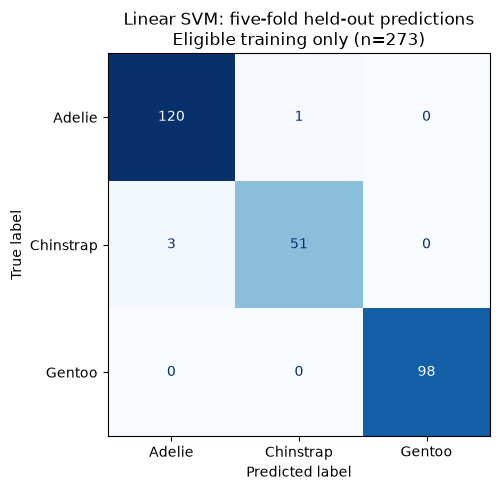

Correct / incorrect: 269 4
All held-out SVM errors, in original source-row order; no rows are removed


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species,predicted_species
73,45.8,18.9,197.0,4150.0,Adelie,Chinstrap
296,42.4,17.3,181.0,3600.0,Chinstrap,Adelie
306,40.9,16.6,187.0,3200.0,Chinstrap,Adelie
340,43.5,18.1,202.0,3400.0,Chinstrap,Adelie


In [17]:
svm_precision, svm_recall, svm_f1, svm_support = precision_recall_fscore_support(
    y_train, svm_oof, labels=CLASS_ORDER, average=None, zero_division=0)
svm_species_scores = pd.DataFrame({'precision': svm_precision, 'recall': svm_recall,
                                  'F1': svm_f1, 'support': svm_support}, index=CLASS_ORDER)
display(svm_species_scores.round(4))

classification_summary = all_model_comparison.copy()
classification_summary.loc['Linear SVM (C=1)'] = [accuracy_score(y_train, svm_oof), svm_f1.mean()]
print('Same held-out development observations; mean_species_F1 is macro-F1')
display(classification_summary.round(4))
display(svm_fold_results[['validation_accuracy', 'validation_mean_F1']].agg(['mean', 'std']).round(4))

svm_matrix = confusion_matrix(y_train, svm_oof, labels=CLASS_ORDER)
assert svm_matrix.sum() == len(y_train)
svm_tp = np.diag(svm_matrix)
manual_svm_f1 = 2 * svm_tp / (svm_matrix.sum(axis=0) + svm_matrix.sum(axis=1))
np.testing.assert_allclose(manual_svm_f1, svm_f1)
assert int(svm_tp.sum()) == int((svm_oof == y_train).sum())
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(svm_matrix, display_labels=CLASS_ORDER).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Linear SVM: five-fold held-out predictions' + chr(10) + 'Eligible training only (n=273)')
fig.tight_layout()
plt.show()
print('Correct / incorrect:', int((svm_oof == y_train).sum()), int((svm_oof != y_train).sum()))
svm_errors = training_view.loc[svm_oof != y_train, FEATURES + [TARGET]].copy()
svm_errors['predicted_species'] = svm_oof.loc[svm_errors.index]
print('All held-out SVM errors, in original source-row order; no rows are removed')
display(svm_errors)

## 23. Interpret this fixed linear SVM

**Held-out result:** 269 of 273 observations are correct (**98.53% accuracy**). Per-species F1 is **0.9836 for Adelie, 0.9623 for Chinstrap and 1.0000 for Gentoo**; their equal-weight mean is **0.9820**. The confusion matrix has one Adelie predicted as Chinstrap and three Chinstrap predicted as Adelie. These are development results, not final-test results.

**Does SVM improve on logistic regression here?** No. Both fixed procedures give the same held-out predictions, including source rows **73, 296, 306 and 340** as the four errors. Their training objectives and learned boundaries are different; matching predictions on this sample do not make the algorithms equivalent. The shallow tree has 92.31% accuracy and mean F1 0.9079; the majority reference has 44.32% and 0.2047. This limited comparison does not establish a universal ranking or a statistically significant difference.

**Fit versus validation:** SVM fit accuracy ranges from 98.17% to 99.54%. Validation is 100% in three folds and approximately 96.3% in two. Its mean fold accuracy is 0.9853 (sample SD 0.0201); mean fold F1 is 0.9812 (SD 0.0257), distinct from pooled F1 0.9820. A held-out score can exceed its fit score because the subsets differ. These descriptive variations are not confidence intervals. Perfect Gentoo recall applies only to these 98 held-out observations, not every future Gentoo penguin.

**What did `fit` learn?** Each round selects 22-25 distinct fit observations as support vectors across its three binary problems. In round 1 there are 22: nine Adelie, nine Chinstrap and four Gentoo, from 218 fit rows. They shape the pairwise boundaries; they are not 22 errors or 22 validation rows. All fits converged; the largest per-pair solver count is 137 iterations, below the fixed 10,000 ceiling. Iterations are not epochs.

**What we learn:** logistic regression converts scores into model probabilities, a tree learns threshold rules and a linear SVM trades margin width against hinge loss. We can understand all three using the same inputs and evaluation. No nonlinear kernel, `C` search, probability calibration, new feature, row removal or final-test access is introduced by this SVM comparison. The EDA informed this design, and adding another model after reviewing development scores does not create independent evidence.

## 24. A new task: predict body mass, not species

**Question:** can bill length, bill depth and flipper length predict **body mass in grams** better than a simple constant reference?

Classification predicted a species label. Regression predicts a number. We now define **three inputs**, `bill_length_mm`, `bill_depth_mm` and `flipper_length_mm`, and response `body_mass_g`. **Body mass leaves the input matrix.** Species, island, sex and year are not regression predictors in this first experiment. We do not reuse classification accuracy or F1 to judge grams.

The original 275 training / 69 reserved-test allocation is unchanged. It was stratified by species when fixed earlier; it is not a new mass-stratified split. Within training we check complete records for these three inputs **and** the mass response. Here the same two source rows are incomplete, leaving 273 eligible observations. This coincidence does not make input and response roles interchangeable. Nine observations with missing sex remain usable.

The separate variables below avoid overwriting the classification inputs, labels or folds. No source row is deleted or filled, and this development-preparation block does not inspect final-test eligibility or mass values. Those are used only in section 33.
`train` is the original 275-row development table. `reg_eligible` marks rows with all three inputs and the response recorded; `reg_training` copies those 273 rows. `X_reg` contains the three input columns and `y_reg` contains their recorded weights. These lines prepare data; they do not train a model.


In [18]:
REG_FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']
REG_TARGET = 'body_mass_g'
reg_required = REG_FEATURES + [REG_TARGET]
reg_eligible = train[reg_required].notna().all(axis=1)
reg_training = train.loc[reg_eligible].copy()
X_reg = reg_training[REG_FEATURES].copy()
y_reg = reg_training[REG_TARGET].copy()
reg_excluded_ids = train.index[~reg_eligible].tolist()
assert REG_TARGET not in X_reg.columns and 'species' not in X_reg.columns
assert X_reg.index.equals(y_reg.index)
assert X_reg.notna().all().all() and y_reg.notna().all()
assert set(X_reg.index).isdisjoint(test_ids)
assert len(reg_training) + len(reg_excluded_ids) == len(train)
assert len(reg_training) == 273 and reg_excluded_ids == [3, 271]
print('Regression input matrix / numeric response:', X_reg.shape, y_reg.shape)
print('Eligible / excluded training rows:', len(reg_training), len(reg_excluded_ids))
print('Excluded source IDs:', reg_excluded_ids)
print('Inputs in mm; response in grams. The original CSV and split are unchanged.')

Regression input matrix / numeric response: (273, 3) (273,)
Eligible / excluded training rows: 273 2
Excluded source IDs: [3, 271]
Inputs in mm; response in grams. The original CSV and split are unchanged.


## 25. What does linear regression learn?

For one input, a line is $\hat y=\beta_0+\beta_1x$. We use **multiple linear regression**, with three inputs:

$$\widehat{\mathrm{mass}}=\beta_0+\beta_1\,\mathrm{bill\ length}+\beta_2\,\mathrm{bill\ depth}+\beta_3\,\mathrm{flipper\ length}.$$

The inputs are in millimetres and the output is in grams. The intercept $\beta_0$ and three coefficients $\beta_j$ are **learned parameters**, not values we choose by hand. A coefficient describes a change in predicted grams per additional millimetre **holding the other two inputs fixed**. It is not a causal effect. Correlated measurements can make individual coefficients difficult to interpret. The intercept at three zero measurements is a mathematical reference, not a plausible penguin.

**Where does learning come from?** Define a fit residual $e_i=y_i-\hat y_i$. Ordinary least squares (OLS) chooses the parameters that minimise the **residual sum of squares** on fit observations:

$$\mathrm{RSS}(\beta)=\sum_{i\in\mathrm{fit}}(y_i-\hat y_i)^2.$$

With $n$ fixed, minimising RSS is equivalent to minimising its mean, MSE. Squaring penalises large errors more. For instance, residuals 100 g and -200 g contribute $100^2+(-200)^2=50{,}000$ square grams. The numerical least-squares solver computes coefficients from the fit table; **this `LinearRegression` implementation does not run our own gradient-descent loop**. Training happens at `.fit`, just as for classifiers, but the objective is different.

**What do we choose?** `LinearRegression(fit_intercept=True, positive=False)` learns an intercept and allows either coefficient sign. There is no regularisation `C` or `alpha`, learning rate or epoch count here. Numerical solver tolerances are implementation settings, not a search for predictive hyperparameters. The runtime versions are recorded at the top of the notebook.

We retain original measurement units and do not scale or impute in this first OLS experiment. Scaling is not required for this small, unregularised least-squares fit; it would change coefficient units. Any later learned preprocessing must still be fitted within each fit subset. No polynomial terms, interactions, feature selection or coefficient significance tests are added.

**Reference:** `DummyRegressor(strategy='median')` learns the fit subset's median mass and predicts it for every held-out observation, ignoring the measurements. The median minimises absolute error among constant predictions on the fit set. It is a relevant reference because our main metric is MAE; it is not the optimal constant for squared error, for which the fit mean would be the reference.

### 25.1 Errors in grams: MAE, RMSE and supplementary R-squared

For $n$ held-out observations, with $e_i=y_i-\hat y_i$:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|e_i|,\qquad \mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i e_i^2}.$$

**MAE is the main metric.** It is the average absolute error in grams: lower is better. It does not mean every prediction is within that distance. **RMSE** is also in grams, but gives larger errors more influence. In the 100 g / -200 g example, MAE is 150 g and RMSE is $\sqrt{25{,}000}\approx158.1$ g.

We also report **$R^2$** as a supplementary dimensionless summary:

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

Here $\bar y$ is the mean of the observations being scored, used only in the metric denominator; it is not fitted into either predictor. A score of 1 is perfect on these observations, 0 matches the squared error of their constant mean, and negative values are possible. It is **not classification accuracy**, a correlation coefficient, or the proportion of predictions that are correct. Do not assume that held-out $R^2$ lies between 0 and 1. We compare both regressors on the same rows and read MAE/RMSE before $R^2$.

**Pearson r versus R-squared:** Pearson r measures signed linear association between two variables, from -1 to +1. Our held-out, three-input regression R-squared is not automatically r squared. In simple OLS with an intercept on the fit sample the identity holds for input/response correlation; it must not be assumed here.

## 26. Five regression validation rounds: fixed before fitting

We use **`KFold(n_splits=5, shuffle=True, random_state=42)`**, a separate saved fold list for regression. We do not stratify continuous mass values. There are again three validation groups of 55 and two of 54 observations, with fit sizes 218 or 219; membership need not match the classification folds.

In each round, construct a fresh median reference and a fresh linear regressor. Fit both on exactly the same fit rows, then predict exactly the same held-out rows. Each of the 273 observations receives one prediction from each method that was fitted without it. Fold medians, coefficients and intercepts come from fit labels only. Validation mass is used to calculate errors after prediction.

The visible loop records fit and validation MAE, validation RMSE and R-squared. Fit errors describe the data the method learned from; they are not substituted for validation errors. Pooling all held-out predictions and averaging fold scores are different summaries. Fold standard deviations describe variation, not confidence intervals.

These are fixed teaching models, not a hyperparameter search or nested cross-validation. The final 69 observations remain reserved. This regression question follows training EDA and earlier classification development, so the scores are development evidence, not a newly independent final evaluation.

In [19]:
from sklearn.model_selection import KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

reg_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_folds = list(reg_cv.split(X_reg))
reg_oof = pd.DataFrame(np.nan, index=y_reg.index, columns=['Median reference', 'Linear regression'])
reg_coverage = np.zeros(len(X_reg), dtype=int)
reg_fold_rows = []

for fold_number, (fit_positions, validation_positions) in enumerate(reg_folds, start=1):
    X_fit, y_fit = X_reg.iloc[fit_positions], y_reg.iloc[fit_positions]
    X_validation, y_validation = X_reg.iloc[validation_positions], y_reg.iloc[validation_positions]
    assert set(X_fit.index).isdisjoint(X_validation.index)
    assert set(X_fit.index).union(X_validation.index) == set(X_reg.index)
    assert set(X_fit.index).union(X_validation.index).isdisjoint(test_ids)
    models = {
        'Median reference': DummyRegressor(strategy='median'),
        'Linear regression': LinearRegression(fit_intercept=True, positive=False),
    }
    for model_name, reg_model in models.items():
        # TRAIN HERE: learn a fit median, or the intercept and three OLS coefficients.
        reg_model.fit(X_fit, y_fit)
        # PREDICT HERE: validation rows change no fitted quantities.
        held_out = reg_model.predict(X_validation)
        fit_predictions = reg_model.predict(X_fit)
        assert np.isfinite(held_out).all()
        reg_oof.loc[X_validation.index, model_name] = held_out
        reg_fold_rows.append({
            'fold': fold_number, 'model': model_name,
            'fit_n': len(X_fit), 'validation_n': len(X_validation),
            'fit_MAE_g': mean_absolute_error(y_fit, fit_predictions),
            'validation_MAE_g': mean_absolute_error(y_validation, held_out),
            'validation_RMSE_g': root_mean_squared_error(y_validation, held_out),
            'validation_R2': r2_score(y_validation, held_out),
        })
        if model_name == 'Median reference':
            np.testing.assert_allclose(held_out, y_fit.median())
        if fold_number == 1 and model_name == 'Linear regression':
            first_regressor = reg_model
            first_regression_coefficients = pd.Series(reg_model.coef_, index=REG_FEATURES,
                                                      name='grams_per_mm')
            first_regression_intercept = float(reg_model.intercept_)
            first_regression_example = X_validation.iloc[[0]].copy()
            first_regression_actual = float(y_validation.iloc[0])
    reg_coverage[validation_positions] += 1

assert (reg_coverage == 1).all() and reg_oof.notna().all().all()
reg_fold_results = pd.DataFrame(reg_fold_rows).set_index(['fold', 'model'])
display(reg_fold_results.round(3))
print('Round 1 learned coefficients: grams per mm, conditional on the other inputs')
display(first_regression_coefficients.round(3).to_frame())
print('Round 1 intercept (g):', round(first_regression_intercept, 3))
print('Round 1 validation example, source ID:', int(first_regression_example.index[0]))
display(first_regression_example)
manual_mass = first_regression_intercept + float(
    first_regression_example.to_numpy()[0] @ first_regression_coefficients.to_numpy())
np.testing.assert_allclose(manual_mass, first_regressor.predict(first_regression_example)[0])
print('Intercept + three coefficient contributions (g):', round(manual_mass, 2))
print('Recorded mass (g):', first_regression_actual)
print('Residual = recorded - predicted (g):', round(first_regression_actual - manual_mass, 2))

fit_n  validation_n  fit_MAE_g  validation_MAE_g  \
fold model                                                                 
1    Median reference     218            55    692.317           600.455   
     Linear regression    218            55    324.752           303.162   
2    Median reference     218            55    653.555           755.682   
     Linear regression    218            55    311.255           353.066   
3    Median reference     218            55    654.472           740.909   
     Linear regression    218            55    310.760           362.613   
4    Median reference     219            54    682.306           629.630   
     Linear regression    219            54    329.741           288.811   
5    Median reference     219            54    673.744           668.056   
     Linear regression    219            54    322.610           318.872   

                        validation_RMSE_g  validation_R2  
fold model                                                
1    Median reference             738.403         -0.000  
     Linear regression            392.716          0.717  
2    Median reference             902.608         -0.152  
     Linear regression            444.327          0.721  
3    Median reference             898.041         -0.074  
     Linear regression            443.191          0.738  
4    Median reference             784.146         -0.034  
     Linear regression            361.420          0.780  
5    Median reference             779.029         -0.004  
     Linear regression            391.329          0.747

Round 1 learned coefficients: grams per mm, conditional on the other inputs


,grams_per_mm
bill_length_mm,-0.327
bill_depth_mm,36.404
flipper_length_mm,54.363


Round 1 intercept (g): -7313.17
Round 1 validation example, source ID: 8


,bill_length_mm,bill_depth_mm,flipper_length_mm
8,34.1,18.1,193.0


Intercept + three coefficient contributions (g): 3826.68
Recorded mass (g): 3475.0
Residual = recorded - predicted (g): -351.68


## 27. Evaluate held-out predictions, not the fit table

Calculate a single summary from all 273 held-out predictions for each method. We keep the units in the column names. Then show the mean and standard deviation of the five fold scores separately. The main question is whether using measurements reduces **validation MAE** compared with the median reference.

The direct calculations below check MAE, RMSE and R-squared from residuals. They do not train another model. A positive residual means recorded mass exceeds predicted mass: the model **underestimates** that observation. A negative residual means it **overestimates** it. We show a few rows in original source order to connect formulas, predictions and real observations.

In [20]:
reg_summary_rows = []
for model_name in reg_oof.columns:
    predictions = reg_oof[model_name]
    errors = y_reg - predictions
    mae = mean_absolute_error(y_reg, predictions)
    rmse = root_mean_squared_error(y_reg, predictions)
    r2 = r2_score(y_reg, predictions)
    np.testing.assert_allclose(mae, np.abs(errors).mean())
    np.testing.assert_allclose(rmse, np.sqrt(np.square(errors).mean()))
    np.testing.assert_allclose(r2, 1 - np.square(errors).sum() / np.square(y_reg - y_reg.mean()).sum())
    reg_summary_rows.append({'model': model_name, 'MAE_g': mae, 'RMSE_g': rmse, 'R2': r2})
reg_summary = pd.DataFrame(reg_summary_rows).set_index('model')
print('Pooled held-out regression scores; 273 identical observations per method')
display(reg_summary.round(3))
print('Separate fold summaries; standard deviation is descriptive')
display(reg_fold_results.groupby('model')[['validation_MAE_g', 'validation_RMSE_g',
                                           'validation_R2']].agg(['mean', 'std']).round(3))
reg_examples = pd.DataFrame({'recorded_mass_g': y_reg,
                             'median_prediction_g': reg_oof['Median reference'],
                             'linear_prediction_g': reg_oof['Linear regression']})
reg_examples['linear_residual_g'] = y_reg - reg_oof['Linear regression']
print('First five source rows, not selected by prediction quality')
display(reg_examples.head().round(2))

Pooled held-out regression scores; 273 identical observations per method


,MAE_g,RMSE_g,R2
model,,,
Median reference,679.167,823.484,-0.048
Linear regression,325.462,408.100,0.743


Separate fold summaries; standard deviation is descriptive


validation_MAE_g         validation_RMSE_g          \
                              mean     std              mean     std   
model                                                                  
Linear regression          325.305  31.725           406.596  36.157   
Median reference           678.946  67.896           820.445  75.060   

                  validation_R2         
                           mean    std  
model                                   
Linear regression         0.741  0.025  
Median reference         -0.053  0.063

First five source rows, not selected by prediction quality


,recorded_mass_g,median_prediction_g,linear_prediction_g,linear_residual_g
0,3750.0,4050.0,3213.70,536.30
2,3250.0,4050.0,3920.53,-670.53
4,3450.0,3987.5,3843.68,-393.68
5,3650.0,4050.0,3709.88,-59.88
6,3625.0,4050.0,3209.39,415.61


## 28. Read two diagnostic figures

**Observed versus predicted:** the diagonal is perfect prediction. Predictions below it underestimate mass; predictions above it overestimate. The median reference produces almost horizontal bands because each fold predicts one fit median. A tighter diagonal cloud for the linear model indicates lower errors on these observations, not a guarantee for new populations.

**Residual versus predicted:** each point is an out-of-fold error from the linear model, using `recorded - predicted`. The zero line means no error. A curve could suggest missing nonlinear structure; a funnel could suggest changing error spread. This small visual check does not prove linearity, equal variance, normality or independent errors. It combines five fitted models, so its mean residual need not be exactly zero, unlike a fit-table OLS identity with an intercept.

All eligible observations, including large errors, are shown. No plot changes the target, removes a row or chooses a new model. We do not label these as final-test figures.

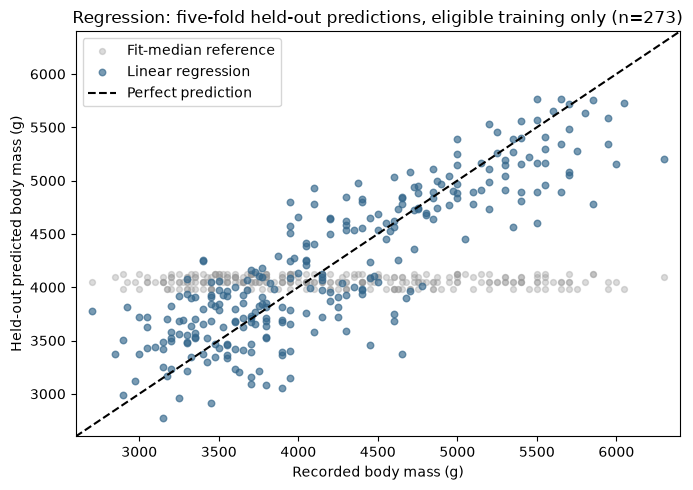

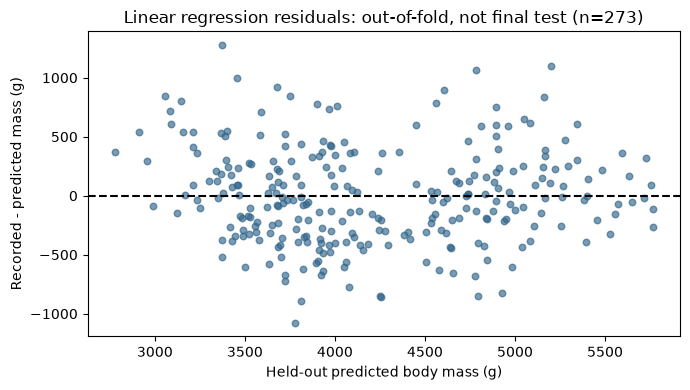

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_reg, reg_oof['Median reference'], alpha=0.35, s=18,
           label='Fit-median reference', color='#999999')
ax.scatter(y_reg, reg_oof['Linear regression'], alpha=0.65, s=22,
           label='Linear regression', color='#32658a')
limits = [min(y_reg.min(), reg_oof.min().min()) - 100,
          max(y_reg.max(), reg_oof.max().max()) + 100]
ax.plot(limits, limits, color='black', linestyle='--', label='Perfect prediction')
ax.set(xlabel='Recorded body mass (g)', ylabel='Held-out predicted body mass (g)',
       title='Regression: five-fold held-out predictions, eligible training only (n=273)',
       xlim=limits, ylim=limits)
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(reg_oof['Linear regression'], y_reg - reg_oof['Linear regression'],
           alpha=0.65, s=22, color='#32658a')
ax.axhline(0, color='black', linestyle='--')
ax.set(xlabel='Held-out predicted body mass (g)', ylabel='Recorded - predicted mass (g)',
       title='Linear regression residuals: out-of-fold, not final test (n=273)')
fig.tight_layout()
plt.show()

## 29. Interpret the first regression comparison

**Do measurements help here?** Yes, in this fixed development comparison. The median reference has **MAE 679.17 g, RMSE 823.48 g and R-squared -0.048**. Linear regression has **MAE 325.46 g, RMSE 408.10 g and R-squared 0.743** on the same 273 held-out observations. The MAE reduction is approximately **52.1%** relative to that reference. It is not a 52.1% improvement over every possible model or a guaranteed error for an individual penguin.

**Why is the reference's R-squared negative?** Each fold predicts its fit median, not the scored observations' mean used in the R-squared denominator. Its held-out squared error is slightly greater than that denominator. The negative value is valid, not a software error. The reference was chosen for absolute-error evaluation, not to minimise RMSE.

**Are results stable across folds?** Linear validation MAE ranges from **288.81 to 362.61 g**, compared with fit MAE **310.76 to 329.74 g**. It improves on the median reference in each fold. Different subsets can make validation error lower than fit error. The pooled scores and five fold scores describe this particular development exercise; neither is a confidence interval or a final-test score.

**Can we read the fitted formula?** In round 1 the learned intercept is approximately **-7313.17 g**, and the coefficients are **-0.33, 36.40 and 54.36 g/mm** for bill length, bill depth and flipper length. The displayed source-row-8 example gives **3826.68 g predicted versus 3475 g recorded**, a residual of **-351.68 g**: an overestimate. Printed coefficients are rounded for reading; the code uses full-precision arrays to calculate 3826.68 g. This is one fold's fitted formula, not the final all-development regressor. The small negative bill-length coefficient is conditional on the other two correlated inputs; it does not prove bill length is useless or has a causal negative effect. Zero physical measurements are outside the data, so the intercept has no standalone biological interpretation.

**What do the figures show?** Measurement-based predictions follow the diagonal more closely than the almost horizontal reference. They still miss some observations substantially: the held-out residual range is approximately **-1075.68 to +1276.00 g**. For example, the 6300 g observation is predicted at 5198.52 g. All such observations remain in the data. MAE is an average, and the larger RMSE reflects the greater weight of large errors. Residuals appear on both sides of zero; this plot alone does not establish normality, constant variance, independence or the absence of nonlinear structure.

**What we learn:** changing the response changes the input set, loss and evaluation metrics. OLS learns coefficients by minimising fit squared error, while we judge its predictions primarily by held-out absolute error in grams. Neither coefficient magnitude nor a p-value automatically selects features. No new data, test inspection, imputation, transformation search, regression tree or regularisation search was introduced. These small-sample results describe within-sample generalisation, not other islands, years or penguin populations.

## 30. Initial development comparison and references

The fixed logistic and linear-SVM procedures each classify 269 of 273 held-out development observations correctly. The depth-3 tree classifies 252 correctly. The separate four-depth search selects depth 4 on a tie with depth 5; this is a selection result, not an independent assessment.

For mass prediction, ordinary least squares reduces held-out MAE from 679.17 g for the median reference to 325.46 g. These results describe the present sample and preparation rules. They do not establish performance on new islands, future years or the reserved final test.

The experiments show the difference between choosing settings, fitting a model, predicting new rows and evaluating errors. The following extension completes nested selection and final evaluation; notebook 03 covers unsupervised learning.

### Method references

- [F1 and per-class metrics](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html)
- [logistic regression and its objective](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)
- [LogisticRegression settings](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Decision trees and Gini](https://scikit-learn.org/stable/modules/tree.html#mathematical-formulation)
- [DecisionTreeClassifier settings](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [SVM user guide](https://scikit-learn.org/stable/modules/svm.html)
- [SVC implementation and settings](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [median reference](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html)
- [regression evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)

- [Grid search and hyperparameter selection](https://scikit-learn.org/stable/modules/grid_search.html)

### AI assistance

AI assistance was used for explanations, Python drafts, debugging and editing. The author is responsible for reviewing, understanding and explaining the submitted work. The reports record the checks performed and a documented correction. No personal learning reflection is written on the author's behalf.


## 31. Two additional classifiers: understand before fitting

The initial comparisons above are development exercises. This extension compares two more classical methods using the same four physical measurements and species response. Development has already been explored; nested cross-validation does not erase that history. The existing final-test results will not be used to change settings.

### 31.1 K-nearest neighbours (KNN): prediction by similarity

**Idea.** Similar physical measurements may indicate the same species. To predict one new penguin, KNN finds the k closest **fit observations** and chooses the most frequent species among them. It uses all four measurements together, not a separate classifier for each column.

1. Fit StandardScaler on the fit rows: learn a mean and standard deviation for each measurement.
2. Transform the fit rows and store their scaled measurements and species labels in KNN.
3. Transform a held-out query using the **same** learned scaler.
4. Compute distances to stored fit rows, find k nearest neighbours, and count their labels.

For scaled measurements $z_j=(x_j-\mu_j)/s_j$, Euclidean distance is
$$d(z,z_i)=\sqrt{\sum_{j=1}^{4}(z_j-z_{ij})^2}.$$
With uniform votes, the estimated proportion for species c is
$$\hat p(c\mid z)=\frac{1}{k}\sum_{i\in N_k(z)}\mathbf{1}(y_i=c),\qquad
\hat y=\arg\max_c\hat p(c\mid z).$$
The indicator is 1 when a neighbour has species c and 0 otherwise. For example, labels Adelie, Adelie, Chinstrap with k=3 give proportions 2/3, 1/3, 0 and predict Adelie. These proportions are not automatically calibrated probabilities.

**What does `fit` learn?** The pipeline scaler learns means and scales. KNN itself retains the fit examples and may build a search structure; it does not minimise a coefficient loss with gradient descent. `predict` searches those stored examples without changing them. k is a hyperparameter, not something changed inside one KNN fit.

| Item | Setting in this study | Meaning |
|---|---|---|
| `n_neighbors` | Inner search: 3, 5, 9 | How many fit labels contribute. Small k follows local detail; larger k smooths the boundary. |
| `weights` | `uniform` | Each neighbour contributes equally. Distance-weighted voting exists but is not used. |
| `metric`, `p` | `minkowski`, 2 | This is Euclidean distance. No metric search is performed. |
| `algorithm` | `auto` | Library choice of neighbour-search implementation, not another predictive model. |
| Learned quantities | Scaler statistics; stored fit rows and labels | No learned slope or intercept in KNN. |

An odd k prevents some binary vote ties but **does not prevent all ties with three species**. Distance ties at the neighbour boundary can also make row order relevant. Fixed source order supports reproducibility. KNN is sensitive to scale, irrelevant dimensions, local outliers and sample density; a high-dimensional setting is harder than this four-input example. We scale to give the four measurements comparable units, not because scaling guarantees higher scores.

### 31.2 Random Forest: combine diverse fitted trees

**Idea.** One tree can change considerably when its fit data change. A forest combines trees made different by two sources of randomness:

1. For each tree, draw a bootstrap sample: sample fit rows **with replacement**. With `max_samples=None`, there are as many draws as fit rows, but repeated IDs mean fewer distinct observations.
2. At each node, consider a random subset of inputs and search for a useful split using Gini impurity, as explained in the earlier tree section. Here `max_features='sqrt'` gives a nominal subset of two out of four inputs. The library may inspect more if necessary to find a valid split.
3. Grow each tree subject to the chosen depth and leaf limits. Each tree learns its own split features, thresholds and terminal class proportions.
4. For a new observation, obtain the three class probabilities from each tree and **average probabilities across all 100 trees**. Predict the class with the greatest average.

For T trees, scikit-learn calculates
$$\hat p_{RF}(c\mid x)=\frac{1}{T}\sum_{t=1}^{T}\hat p_t(c\mid x),\qquad
\hat y=\arg\max_c\hat p_{RF}(c\mid x).$$
The per-tree probability is the class proportion in its reached leaf, including bootstrap multiplicities. **This is not necessarily the same as taking a majority of the 100 hard class labels.**

For illustration, three trees with probabilities (0.51, 0.49, 0), (0.51, 0.49, 0), and (0, 1, 0) have hard labels Adelie, Adelie, Chinstrap. Hard voting would give Adelie, but the mean probabilities are (0.34, 0.66, 0), so this probability-averaging rule gives Chinstrap. This is a constructed arithmetic example, not an additional experiment.

| Item | Setting in this study | Meaning |
|---|---|---|
| `n_estimators` | 100, fixed | Number of fitted trees; not epochs or gradient steps. |
| `max_depth` | Inner search: 3 or `None` | Cap tree depth, or allow growth until other stopping rules apply. |
| `min_samples_leaf` | Inner search: 1 or 5 | Minimum observations required in a terminal leaf; larger leaves smooth predictions. |
| `max_features` | `sqrt`, fixed | Random input subset considered at each split. |
| `bootstrap`, `max_samples` | `True`, `None` | Fit-row resampling with replacement; full fit-size draws per tree. |
| `criterion`, `min_samples_split` | `gini`, 2 | Split quality and minimum node size for attempting a split. |
| `class_weight`, `ccp_alpha` | `None`, 0 | No class reweighting or cost-complexity post-pruning. |
| `random_state`, `n_jobs` | 42, 1 | Repeatable randomness; sequential computation. |
| Learned quantities | 100 trees: split rules and leaf proportions | Not a single coefficient vector. |

**What happens during training?** `fit` constructs the trees using greedy splits. There is no gradient-descent optimiser or learning rate here. The trees are not trained to correct earlier trees' residuals: that is a boosting idea, not this forest. Scaling is unnecessary because its individual trees split by thresholds; keeping original units also aids interpretation.

Diversity can reduce variance when trees are combined, but they are not statistically independent. More trees do not guarantee a higher score. Forests are less transparent than one small tree, and depth/leaf limits still matter. Out-of-bag assessment and feature-importance analysis are possible extensions but are not performed here. The model can perform worse than a simpler classifier on this small dataset.

**Terminology:** KNN classifies using labelled neighbours. K-means, in notebook 03, finds centroids without species labels. The letter k appears in both names but the algorithms solve different problems.


## 32. Freeze the selection and assessment protocol

Five outer stratified folds evaluate each procedure. Inside each outer fit group, three stratified folds select settings by **mean per-species F1 (macro-F1)**. Only then is the chosen pipeline refitted on that outer fit group and used to predict the outer held-out group. The scaler is inside the pipeline, so it is also refitted separately inside every inner fit.

| Family | Small, fixed search |
|---|---|
| Logistic regression | C = 0.1, 1, 10 |
| Linear SVM | C = 0.1, 1, 10 |
| Decision tree | depth = 2, 3, 4, 5; minimum leaf = 5 |
| KNN | neighbours = 3, 5, 9; uniform votes |
| Random Forest | 100 trees; depth = 3 or unrestricted; minimum leaf = 1 or 5 |

These are **hyperparameters**, chosen between fits. `fit` learns coefficients, stored neighbours or tree splits within a fit. The five outer rounds are not epochs. Regression remains untuned OLS and does not require an inner search.

**Final rules, fixed before test access:** choose the family with highest mean outer macro-F1; exact ties follow the displayed family order. This selected outer score can itself be optimistic after family selection; final assessment uses the reserved test. Search that family's settings again using three development folds, then refit on all eligible development rows. Compare it with the development-majority reference on test. Report accuracy, per-class F1, macro-F1 and confusion counts. No test-based revision. Regression compares OLS with the development-median reference using MAE, RMSE and R-squared.

**Uncertainty:** 95% Wilson accuracy intervals; a pre-specified, two-sided exact McNemar comparison of selected classifier versus majority reference (one classification test); and 5,000 paired row-bootstrap resamples for regression MAE and the MAE reduction versus the median. Bootstrap intervals are percentile approximations conditional on fitted models, not uncertainty from refitting or independence between birds. Do not use fold standard deviations as confidence intervals. No all-pairs significance fishing.


In [22]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from time import perf_counter

families = {
    'Logistic regression': (Pipeline([('scale', StandardScaler()),
        ('model', LogisticRegression(solver='lbfgs', max_iter=1000))]), {'model__C': [0.1, 1, 10]}),
    'Linear SVM': (Pipeline([('scale', StandardScaler()),
        ('model', SVC(kernel='linear', max_iter=10000))]), {'model__C': [0.1, 1, 10]}),
    'Decision tree': (DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED),
        {'max_depth': [2, 3, 4, 5]}),
    'KNN': (Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier(weights='uniform', metric='minkowski', p=2, algorithm='auto'))]),
        {'model__n_neighbors': [3, 5, 9]}),
    'Random Forest': (RandomForestClassifier(n_estimators=100, max_features='sqrt', bootstrap=True,
        criterion='gini', max_samples=None, min_samples_split=2, class_weight=None, ccp_alpha=0.0,
        random_state=SEED, n_jobs=1), {'max_depth': [3, None], 'min_samples_leaf': [1, 5]}),
}
nested_predictions = pd.DataFrame(index=y_train.index, columns=families, dtype=object)
nested_rows = []
first_outer_models = {}  # Retain existing fits for explanation; no extra search.
started = perf_counter()
for outer_round, (fit_pos, held_pos) in enumerate(folds, 1):
    X_fit, y_fit = X_train.iloc[fit_pos], y_train.iloc[fit_pos]
    X_held, y_held = X_train.iloc[held_pos], y_train.iloc[held_pos]
    assert set(X_fit.index).isdisjoint(X_held.index)
    assert set(X_fit.index).union(X_held.index).isdisjoint(test_ids)
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    for name, (estimator, grid) in families.items():
        search = GridSearchCV(clone(estimator), grid, scoring='f1_macro', cv=inner_cv,
                              refit=True, n_jobs=1, error_score='raise')
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            search.fit(X_fit, y_fit)  # Inner fits/select, then refit outer-fit rows only.
        if outer_round == 1 and name in ['KNN', 'Random Forest']:
            first_outer_models[name] = search.best_estimator_
        prediction = search.predict(X_held)  # Outer assessment, no further fit.
        nested_predictions.loc[X_held.index, name] = prediction
        nested_rows.append({'fold': outer_round, 'model': name,
            'inner_best_macro_F1': search.best_score_, 'settings': str(search.best_params_),
            'outer_accuracy': accuracy_score(y_held, prediction),
            'outer_macro_F1': f1_score(y_held, prediction, average='macro'),
            'fit_n': len(X_fit), 'held_n': len(X_held)})
assert nested_predictions.notna().all().all()
nested_results = pd.DataFrame(nested_rows)
nested_summary = nested_results.groupby('model', sort=False).agg(
    mean_outer_F1=('outer_macro_F1', 'mean'), sd_outer_F1=('outer_macro_F1', 'std'),
    mean_outer_accuracy=('outer_accuracy', 'mean'))
selected_family = nested_summary['mean_outer_F1'].idxmax()
print('Nested CV seconds:', round(perf_counter()-started, 2))
display(nested_results)
display(nested_summary.round(4))
print('Family selected using development only:', selected_family)


Nested CV seconds: 23.96


,fold,model,inner_best_macro_F1,settings,outer_accuracy,outer_macro_F1,fit_n,held_n
0,1,Logistic regression,0.976096,{'model__C': 10},1.000000,1.000000,218,55
1,1,Linear SVM,0.982491,{'model__C': 1},1.000000,1.000000,218,55
2,1,Decision tree,0.917335,{'max_depth': 2},0.981818,0.977591,218,55
3,1,KNN,0.969350,{'model__n_neighbors': 3},1.000000,1.000000,218,55
4,1,Random Forest,0.960543,"{'max_depth': 3, 'min_samples_leaf': 1}",0.963636,0.956364,218,55
5,2,Logistic regression,0.988918,{'model__C': 10},1.000000,1.000000,218,55
6,2,Linear SVM,0.988918,{'model__C': 10},0.981818,0.977324,218,55
7,2,Decision tree,0.882429,{'max_depth': 2},0.927273,0.918415,218,55
8,2,KNN,1.000000,{'model__n_neighbors': 3},1.000000,1.000000,218,55
9,2,Random Forest,0.977510,"{'max_depth': None, 'min_samples_leaf': 1}",0.963636,0.955808,218,55


,mean_outer_F1,sd_outer_F1,mean_outer_accuracy
model,,,
Logistic regression,0.9812,0.0257,0.9853
Linear SVM,0.9815,0.0195,0.9854
Decision tree,0.9052,0.0451,0.9229
KNN,0.9812,0.0257,0.9853
Random Forest,0.9483,0.0303,0.9598


Family selected using development only: Linear SVM


### Reading the nested results

The inner score chooses settings; the outer score assesses predictions on observations absent from that search. Different outer rounds can choose different settings. The table above reports mean fold scores, not pooled scores; standard deviations describe variation across dependent rounds and are not confidence intervals. Small differences do not establish superiority. The original fixed logistic/SVM results remain a different experiment.


**Observed comparison.** KNN has mean outer F1 0.9812, close to logistic regression and linear SVM; the forest has 0.9483. This does not mean that forests are generally worse. These are small-sample results of the fixed searches. KNN selected k=3/3/5/9/5 across the five outer rounds; the forest selected different depth/leaf settings. No selection was made using the final test.

**Where training actually occurs:** `families` defines unfitted estimators and candidate settings. `clone` starts a fresh estimator. Each `search.fit(X_fit, y_fit)` performs inner fitting/validation and then refits the chosen pipeline on that outer fit group because `refit=True`. `search.predict(X_held)` assesses it on that outer held-out group. There are 280 estimator fits: (3+3+4+3+4) candidates × 3 inner folds × 5 outer folds, plus 5 families × 5 outer refits. Each forest fit constructs 100 trees. GridSearchCV does not update one forest's depth; it fits different forests under different candidate settings.


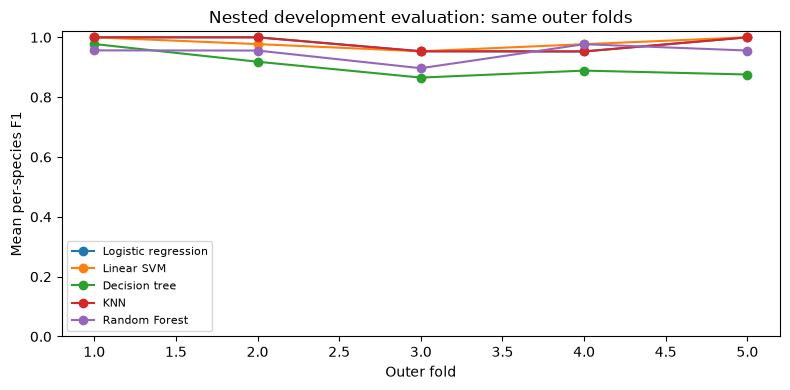

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in families:
    part = nested_results.loc[nested_results['model'].eq(name)]
    ax.plot(part['fold'], part['outer_macro_F1'], marker='o', label=name)
ax.set(xlabel='Outer fold', ylabel='Mean per-species F1', ylim=(0, 1.02),
       title='Nested development evaluation: same outer folds')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()


### 32.1 Follow one KNN prediction by hand

We retain the already-fitted KNN pipeline from **outer round 1**, selected by round number. The query is the first held-out source row in that round, not an example selected for an attractive prediction. It was absent from the stored fit rows and from scaler fitting. No additional fit occurs here.

Read the table of k neighbours: their source IDs, scaled four-input distances and recorded labels. Recompute distances with NumPy and check the uniform class proportions against `predict_proba`. The two-dimensional plot shows only bill length and depth; the actual nearest-neighbour calculation uses **all four scaled measurements**. It is an illustrative projection, not the full distance geometry or a decision boundary.


Outer round 1: fit rows / held-out query source ID / selected k: 218 4 3


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
4,36.7,19.3,193.0,3450.0


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,distance_scaled_4D,species
fit_source_ID,,,,,,
16,38.7,19.0,195.0,3450.0,0.423510,Adelie
86,36.3,19.5,190.0,3800.0,0.510279,Adelie
96,38.1,18.6,190.0,3700.0,0.575278,Adelie


,neighbour_count,uniform_probability
species,,
Adelie,3,1.0
Chinstrap,0,0.0
Gentoo,0,0.0


Predicted / recorded species: Adelie Adelie


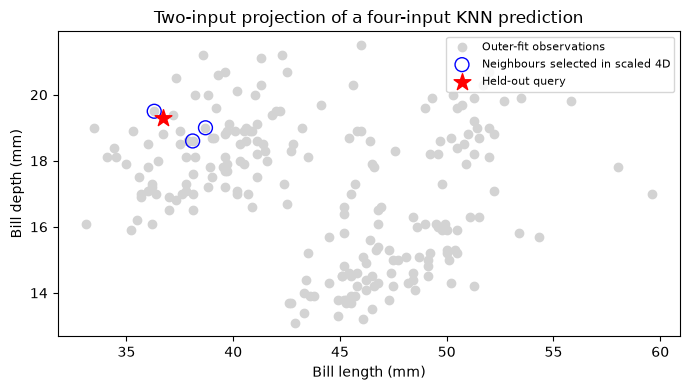

In [24]:
first_fit_pos, first_held_pos = folds[0]
explain_fit = X_train.iloc[first_fit_pos]
explain_labels = y_train.iloc[first_fit_pos]
query = X_train.iloc[first_held_pos[:1]]
assert query.index[0] not in explain_fit.index and query.index[0] not in test_ids
knn_pipeline = first_outer_models['KNN']
knn_scaler = knn_pipeline.named_steps['scale']
knn = knn_pipeline.named_steps['model']
fit_scaled = knn_scaler.transform(explain_fit)
query_scaled = knn_scaler.transform(query)
np.testing.assert_allclose(knn_scaler.mean_, explain_fit.mean())
distances, positions = knn.kneighbors(query_scaled)
manual_distances = np.sqrt(np.square(fit_scaled-query_scaled[0]).sum(axis=1))
np.testing.assert_allclose(distances[0], manual_distances[positions[0]], atol=1e-10)
neighbours = explain_fit.iloc[positions[0]].copy()
neighbours['distance_scaled_4D'] = distances[0]
neighbours['species'] = explain_labels.iloc[positions[0]].to_numpy()
neighbours.index.name = 'fit_source_ID'
counts = neighbours['species'].value_counts().reindex(knn.classes_, fill_value=0)
manual_probabilities = counts.to_numpy()/knn.n_neighbors
np.testing.assert_allclose(manual_probabilities, knn.predict_proba(query_scaled)[0])
manual_label = knn.classes_[manual_probabilities.argmax()]
assert manual_label == knn_pipeline.predict(query)[0]
print('Outer round 1: fit rows / held-out query source ID / selected k:',
      len(explain_fit), query.index[0], knn.n_neighbors)
display(query)
display(neighbours)
display(pd.DataFrame({'neighbour_count': counts, 'uniform_probability': manual_probabilities}))
print('Predicted / recorded species:', manual_label, y_train.loc[query.index[0]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(explain_fit['bill_length_mm'], explain_fit['bill_depth_mm'],
           color='lightgrey', label='Outer-fit observations')
ax.scatter(neighbours['bill_length_mm'], neighbours['bill_depth_mm'],
           facecolors='none', edgecolors='blue', s=100, label='Neighbours selected in scaled 4D')
ax.scatter(query['bill_length_mm'], query['bill_depth_mm'], marker='*',
           color='red', s=160, label='Held-out query')
ax.set(xlabel='Bill length (mm)', ylabel='Bill depth (mm)',
       title='Two-input projection of a four-input KNN prediction')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()


### 32.2 Inspect the forest's resampling and probability average

Use the forest already selected and refitted in outer round 1 and the **same query**. Print the learned depth and number of leaves for the first five trees, their bootstrap draw counts and distinct source-row counts. A draw position refers to an outer-fit row, never a held-out/test row. Repeated positions are expected, not duplicate-data cleaning errors.

Each tree receives the query, reaches a leaf and returns three probabilities. The mean over **all 100 trees**, not just the displayed first five, must equal `forest.predict_proba`. The class with the largest mean must equal `forest.predict`. This is an inspection of existing fitted objects, not a new model comparison.


In [25]:
forest = first_outer_models['Random Forest']
query_array = query.to_numpy()
tree_probabilities = np.vstack([tree.predict_proba(query_array)[0] for tree in forest.estimators_])
manual_forest_probability = tree_probabilities.mean(axis=0)
np.testing.assert_allclose(manual_forest_probability, forest.predict_proba(query)[0])
manual_forest_label = forest.classes_[manual_forest_probability.argmax()]
assert manual_forest_label == forest.predict(query)[0]
tree_rows = []
for number, (tree, draws) in enumerate(zip(forest.estimators_, forest.estimators_samples_)):
    source_ids = explain_fit.index.to_numpy()[draws]
    assert set(source_ids).issubset(explain_fit.index)
    assert set(source_ids).isdisjoint(query.index) and set(source_ids).isdisjoint(test_ids)
    tree_rows.append({'tree': number+1, 'bootstrap_draws': len(draws),
        'distinct_fit_rows': len(np.unique(draws)), 'learned_depth': tree.get_depth(),
        'learned_leaves': tree.get_n_leaves()})
print('Trees / chosen depth cap / chosen minimum leaf:',
      len(forest.estimators_), forest.max_depth, forest.min_samples_leaf)
display(pd.DataFrame(tree_rows).head(5))
print('First five trees only (not selected by score):')
display(pd.DataFrame(tree_probabilities[:5], columns=forest.classes_,
                     index=pd.Index(range(1, 6), name='tree')).round(4))
print('Average across all trees:')
display(pd.Series(manual_forest_probability, index=forest.classes_, name='mean_probability').round(4))
print('Predicted / recorded species:', manual_forest_label, y_train.loc[query.index[0]])
print('Probability-averaging rule verified; no optimiser or new fit was called.')


Trees / chosen depth cap / chosen minimum leaf: 100 3 1


,tree,bootstrap_draws,distinct_fit_rows,learned_depth,learned_leaves
0,1,218,141,3,6
1,2,218,139,3,7
2,3,218,136,3,4
3,4,218,143,3,6
4,5,218,134,3,6


First five trees only (not selected by score):


,Adelie,Chinstrap,Gentoo
tree,,,
1,1.0000,0.0000,0.0
2,0.3333,0.6667,0.0
3,1.0000,0.0000,0.0
4,1.0000,0.0000,0.0
5,0.8608,0.1392,0.0


Average across all trees:


Adelie       0.9153
Chinstrap    0.0844
Gentoo       0.0003
Name: mean_probability, dtype: float64

Predicted / recorded species: Adelie Adelie
Probability-averaging rule verified; no optimiser or new fit was called.


## 33. Final refit, then the reserved test

This is the first modelling use of the reserved test. Running this notebook again reproduces the same evaluation, but must not become a way to tune against the test. The task-specific complete-case rule is unchanged. The selected classifier, reference, OLS and median are fitted using development only. No family is changed after test scores are shown.


Reserved / classifier eligible / regression eligible: 69 69 69
Classifier exclusions: []
Selected family and final development settings: Linear SVM {'model__C': 10}


,n,accuracy,macro_F1
model,,,
Majority reference,69,0.4348,0.2020
Linear SVM,69,0.9855,0.9829


,precision,recall,F1,support
Adelie,1.0000,0.9667,0.9831,30
Chinstrap,0.9333,1.0000,0.9655,14
Gentoo,1.0000,1.0000,1.0000,25


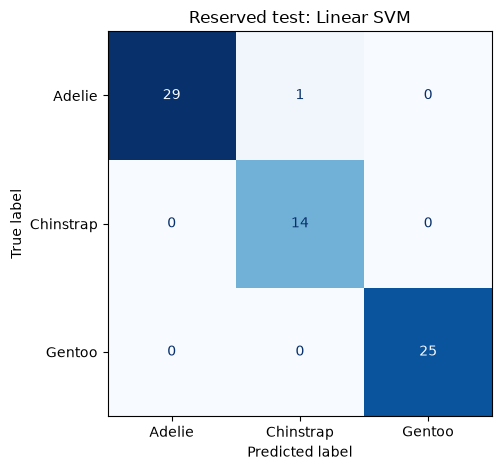

,n,MAE_g,RMSE_g,R2
model,,,,
Median reference,69,644.565,793.948,-0.021
Linear regression,69,276.834,348.582,0.803


In [26]:
estimator, grid = families[selected_family]
final_search = GridSearchCV(clone(estimator), grid, scoring='f1_macro',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    refit=True, n_jobs=1, error_score='raise')
with warnings.catch_warnings():
    warnings.simplefilter('error', ConvergenceWarning)
    final_search.fit(X_train, y_train)
final_reference = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
final_regressor = LinearRegression().fit(X_reg, y_reg)
final_median = DummyRegressor(strategy='median').fit(X_reg, y_reg)
# TEST OPENS HERE: the protocol and all fits above are already fixed.
test = penguins.loc[test_ids].copy()
test_view = test.loc[test[FEATURES + [TARGET]].notna().all(axis=1)].copy()
reg_test = test.loc[test[REG_FEATURES + [REG_TARGET]].notna().all(axis=1)].copy()
X_test, y_test = test_view[FEATURES], test_view[TARGET]
assert set(X_test.index).isdisjoint(X_train.index)
print('Reserved / classifier eligible / regression eligible:', len(test), len(test_view), len(reg_test))
print('Classifier exclusions:', sorted(set(test.index)-set(test_view.index)))
print('Selected family and final development settings:', selected_family, final_search.best_params_)
final_predictions = final_search.predict(X_test)
reference_predictions = final_reference.predict(X_test)
test_classification = pd.DataFrame([
    {'model': name, 'n': len(y_test), 'accuracy': accuracy_score(y_test, pred),
     'macro_F1': f1_score(y_test, pred, labels=CLASS_ORDER, average='macro', zero_division=0)}
    for name, pred in [('Majority reference', reference_predictions), (selected_family, final_predictions)]
]).set_index('model')
display(test_classification.round(4))
p, r, f, support = precision_recall_fscore_support(y_test, final_predictions,
    labels=CLASS_ORDER, zero_division=0)
display(pd.DataFrame({'precision': p, 'recall': r, 'F1': f, 'support': support}, index=CLASS_ORDER).round(4))
ConfusionMatrixDisplay.from_predictions(y_test, final_predictions, labels=CLASS_ORDER,
    cmap='Blues', colorbar=False)
plt.title('Reserved test: '+selected_family); plt.tight_layout(); plt.show()
reg_test_predictions = final_regressor.predict(reg_test[REG_FEATURES])
reg_reference_predictions = final_median.predict(reg_test[REG_FEATURES])
test_regression = pd.DataFrame([
    {'model': name, 'n': len(reg_test), 'MAE_g': mean_absolute_error(reg_test[REG_TARGET], pred),
     'RMSE_g': root_mean_squared_error(reg_test[REG_TARGET], pred),
     'R2': r2_score(reg_test[REG_TARGET], pred)}
    for name, pred in [('Median reference', reg_reference_predictions), ('Linear regression', reg_test_predictions)]
]).set_index('model')
display(test_regression.round(3))


## 34. Uncertainty: what can this small test tell us?

For accuracy $\hat p=k/n$, the Wilson interval uses $z=1.96$ and centre $(\hat p+z^2/(2n))/(1+z^2/n)$, with half-width $z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}/(1+z^2/n)$. It avoids reporting certainty after a perfect small test.

**Paired classification comparison:** count observations where only the selected model is right ($b$) and only the reference is right ($c$). Exact McNemar uses a binomial test of $b$ successes in $b+c$ discordant pairs under probability 0.5. This tests equal error rates for this pre-specified pair, not all families or equal macro-F1.

**Regression bootstrap:** resample row positions with replacement, using the same positions for both predictions and truth. Recompute MAE and the reference-minus-OLS MAE difference. The 2.5th and 97.5th percentiles give an approximate 95% interval. Positive MAE reduction favours OLS. This does not refit models. We assume observations are sufficiently independent and representative; collection structure can weaken that assumption. A small test and a bootstrap cannot establish generalisation to new populations.


**Sampling limits.** Wilson uses an approximate binomial model for accuracy. These observations were allocated by a species-stratified split, and the simplified table does not identify every collection dependency. Our pooled Wilson and row-bootstrap intervals are simple working approximations; they do not model the full collection design or fix class counts in each resample. The paired comparison also assumes sufficiently independent observation pairs. A 95% confidence interval refers to approximate long-run coverage under its assumptions, not a 95% probability that a fixed unknown parameter lies inside this particular interval. Final-model selection, fitting variability and uncertainty about a different population are outside these intervals.


In [27]:
from scipy.stats import binomtest
def wilson(correct, total):
    z = 1.959963984540054
    phat = correct/total
    denominator = 1+z*z/total
    centre = (phat+z*z/(2*total))/denominator
    half = z*np.sqrt(phat*(1-phat)/total+z*z/(4*total**2))/denominator
    return centre-half, centre+half

for name, prediction in [('Majority reference', reference_predictions), (selected_family, final_predictions)]:
    correct = int(np.sum(np.asarray(y_test)==prediction))
    print(name, 'correct:', correct, '/', len(y_test), 'Wilson 95%:', wilson(correct, len(y_test)))
model_right = final_predictions == y_test.to_numpy()
reference_right = reference_predictions == y_test.to_numpy()
b = int(np.sum(model_right & ~reference_right)); c = int(np.sum(~model_right & reference_right))
paired_p = binomtest(b, b+c, p=0.5).pvalue if b+c else 1.0
print('Exact McNemar: model-only correct / reference-only correct / p:', b, c, paired_p)

rng = np.random.default_rng(SEED)
positions = rng.integers(0, len(reg_test), size=(5000, len(reg_test)))
absolute_errors = np.abs(reg_test[REG_TARGET].to_numpy()-reg_test_predictions)
reference_errors = np.abs(reg_test[REG_TARGET].to_numpy()-reg_reference_predictions)
bootstrap_mae = absolute_errors[positions].mean(axis=1)
bootstrap_gain = (reference_errors[positions]-absolute_errors[positions]).mean(axis=1)
mae_interval = np.quantile(bootstrap_mae, [0.025, 0.975])
gain_interval = np.quantile(bootstrap_gain, [0.025, 0.975])
print('OLS MAE, percentile 95% interval (g):', absolute_errors.mean(), mae_interval)
print('Reference-minus-OLS MAE, paired percentile 95% interval (g):',
      (reference_errors-absolute_errors).mean(), gain_interval)
assert np.isclose(absolute_errors.mean(), test_regression.loc['Linear regression', 'MAE_g'])


Majority reference correct: 30 / 69 Wilson 95%: (np.float64(0.32432802635131497), np.float64(0.5521159638472569))
Linear SVM correct: 68 / 69 Wilson 95%: (np.float64(0.9223687753885529), np.float64(0.9974370753554117))
Exact McNemar: model-only correct / reference-only correct / p: 39 1 7.457856554538012e-11
OLS MAE, percentile 95% interval (g): 276.8343727267791 [228.37398705 326.64791142]
Reference-minus-OLS MAE, paired percentile 95% interval (g): 367.73084466452525 [249.68126248 484.86826721]


## 35. Conclusions and limits

Read the initial fixed-model comparison, nested selection assessment and final test as distinct stages. A high score does not establish usefulness in other islands, years or collection settings. Final model choice uses development only; test results are reported without a further search. Classification intervals concern accuracy, not macro-F1; the single paired test concerns selected model versus majority reference. Regression intervals describe conditional test-sample uncertainty. No claim that one measurement-based classifier significantly beats all others is supported by this design.

Notebook 03 addresses descriptive unsupervised learning separately. Species labels never enter its fitted scaler, PCA or K-means. Personal learning conclusions should be written by the author after reviewing and understanding these results.

References: [nested CV](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [KNN](https://scikit-learn.org/stable/modules/neighbors.html), [forests](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees), [binomial test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html).


**Observed final results:** the fixed selection rule chose linear SVM, C=10; 68/69 test observations are correct (accuracy 98.55%, mean species F1 0.9829). The Wilson accuracy interval is 92.24–99.74%. OLS test MAE is 276.83 g, with conditional paired-bootstrap interval 228.37–326.65 g. No post-test tuning was performed. The tiny development advantage of SVM over logistic/KNN is not evidence of superiority.